# Parameter optimization of the denoising algorithm

## 1. Import libraries

In [68]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.figure import Figure
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from src.algorithm import remove_noise as rn
from src.algorithm.summary_plots import FONT, mpl_range, rounded_rect
from src.evaluation.evaluation import read_results
from src.optimization import candidate_search as cs
from src.optimization.splits import N_CV_FOLDS, load_split, split_results

pd.set_option('display.max_columns', 500)

## 2. Score definition

### 2.1. Per-artifact quality

$$
q_i = \frac{\text{clip}(\text{SNR}_i^{\text{out}}, F, C) - F}{C-F}
$$

where $F=-30$ dB and $C=0$ dB.

### 2.2. Global quality

$$
Q = \frac{1}{|\mathcal{S}|}\sum_{s\in\mathcal{S}} Q_s, \qquad
Q_s = \frac{1}{|\mathcal{A}| |\mathcal{C}|}\sum_{a\in\mathcal{A}}\sum_{c\in\mathcal{C}} \bar{q}_{s,a,c}
$$

- $Q_s$: quality at SNR $s$.
- $\mathcal{S}$, $\mathcal{A}$, $\mathcal{C}$: sets of SNR values, artifacts and clean signals (every artifact is inserted into every clean signal).
- $\bar{q}_{s,a,c}$: mean quality of artifact $a$ in clean signal $c$ at SNR $s$ (mean over its $N_{a,c}$ positions):

$$
\bar{q}_{s,a,c} = \frac{1}{N_{a,c}}\sum_{i=1}^{N_{a,c}} q_{s,a,c}^{(i)}
$$

> Each artifact and each clean signal weighs the same, whatever its number of positions $N_{a,c}$.

### 2.3. Number of false positives

$$
FP = \frac{1}{|\mathcal{C}|}\sum_{c\in\mathcal{C}}\bar{n}_c^{\text{false}}, \qquad
\bar{n}_c^{\text{false}} = \frac{1}{|\mathcal{S}| |\mathcal{A}|}\sum_{s\in\mathcal{S}}\sum_{a\in\mathcal{A}} \bar{n}_{s,a,c}^{\text{false}}
$$

- $\bar{n}_c^{\text{false}}$: mean number of false positives of the mixtures of clean signal $c$, averaged as $Q$.
- $\bar{n}_{s,a,c}^{\text{false}}$: mean over the $N_{a,c}$ positions.

### 2.4. Score

$$
S = Q - \lambda\cdot FP
$$

- $\lambda$: penalty of the false positives (see [3.2](#3.2.-Penalty-λ)).

### 2.5. Diagnostics

- Detection per SNR.
- SNR at 50 % detection.
- Conservation.
- False positives per label.
- Local RMS error of the detected artifacts.

In [15]:
F_DB = -30  # dB. Per-artifact quality: q = 0 at SNR_out <= F_DB ...
C_DB = 0    # dB. ... and q = 1 at SNR_out >= C_DB


def quality(snr_out_db, f=F_DB, c=C_DB):
    """
    Per-artifact quality: q = (clip(SNR_out, F, C) - F) / (C - F).

    Parameters
    ----------
    snr_out_db: array-like
        SNR in the artifact zone after the filter (dB)
    f, c: float
        Floor and ceiling of the SNR (dB): q = 0 at SNR_out <= f, q = 1 at SNR_out >= c

    Returns
    -------
    q: array-like
        Quality of each artifact, in [0, 1]
    """
    return (np.clip(snr_out_db, f, c) - f) / (c - f)


def snr_at_50(rate, levels):
    """
    SNR at which the detection rate crosses 0.5 (linear interpolation between levels), as in plot_detection of
    evaluation_denoise.ipynb. The detection decreases as the SNR increases: the last level with rate >= 0.5 is taken
    and interpolated up to the next one.
    +inf: >= 0.5 up to the last level (crossing above the range); -inf: < 0.5 in all of them (below the range).

    Parameters
    ----------
    rate: np.ndarray
        Detection rate at each SNR level
    levels: np.ndarray
        SNR levels (dB), in increasing order

    Returns
    -------
    snr50: float
        SNR at 50 % detection (dB)
    """
    above = rate >= 0.5
    if not above.any():
        return -np.inf
    i = np.where(above)[0].max()
    if i == len(rate) - 1:
        return np.inf
    r0, r1 = rate[i], rate[i + 1]
    return levels[i] + (0.5 - r0) * (levels[i + 1] - levels[i]) / (r1 - r0)


def score(results_df, lam, snr_list=None, f=F_DB, c=C_DB):
    """
    Score S = Q - λ·FP of the results of an experiment with one artifact per mixture (format of experiment_1.csv),
    and its diagnostics (see section 2). Every artifact is inserted into every clean signal, and the means are taken
    first over the positions of each cell (s, a, c), so that each artifact and each clean signal weighs the same
    whatever its number of positions:
    - Q: mean over the positions -> the clean signals -> the artifacts -> the SNR of the quality
    - FP: for each clean signal, mean over the positions -> the artifacts -> the SNR of the number of false positives
      of its mixtures (controls excluded); then mean over the clean signals

    Parameters
    ----------
    results_df: pd.DataFrame
        Results (mixtures + controls), already restricted to the set to evaluate (e.g. tuning signals and artifacts)
    lam: float
        Penalty λ of the false positives
    snr_list: list or None
        SNR values (dB) of the set S. None -> all the SNR of the mixtures. FP uses the mixtures of the same SNR values
    f, c: float
        Floor and ceiling of the per-artifact quality (dB)

    Returns
    -------
    scores: dict
        S, Q, FP and lam
    diagnostics: dict
        - per_snr: pd.DataFrame, one row per SNR: number of mixtures, detection rate Det_s and quality Q_s (averaged
          as Q), mean q of the detected / undetected artifacts and dq = q_det - q_undet (cost of missing an artifact,
          see 3.2), median NMSE out of the artifact zone and median local RMS error (max, mean) after the filter of the
          detected artifacts.
          q_det and q_undet are weighted as in Q (each mixture weighs w_i = 1 / N_{a,c}, number of positions of its
          cell), so that Q_s = Det_s·q_det + (1 - Det_s)·q_undet exactly (see 6.3)
        - snr50: SNR at 50 % detection of all the artifacts (dB; ±inf: crossing out of the SNR range)
        - snr50_art: pd.Series, SNR at 50 % detection of each artifact
        - fp_label: pd.DataFrame, false positives per label of the clean signal: mean over its clean signals of the
          mean per mixture (as FP), mean per control and number of clean signals
        - nmse_control_db: median NMSE of the controls (whole signal)
    """
    df = results_df.assign(snr_db=pd.to_numeric(results_df["snr_db"], errors="coerce"))  # "Control" -> NaN
    is_control = df["art_id"].astype(str) == "Control"
    controls = df[is_control]
    mix = df[~is_control]
    if snr_list is not None:
        mix = mix[mix["snr_db"].isin(snr_list)]
    mix = mix.assign(q=quality(mix["snr_out_db"], f, c), detected=mix["detected"].astype(bool))

    cells = ["snr_db", "art_id", "clean_id"]

    def per_snr_mean(cell_values):
        """Mean of the values of the cells (s, a, c) over the clean signals, then over the artifacts -> one per SNR."""
        return cell_values.groupby(level=["snr_db", "art_id"]).mean().groupby(level="snr_db").mean()

    # ============================================================================ score
    cell_q = mix.groupby(cells)["q"].mean()                   # q̄_{s,a,c}: mean over the positions
    q_snr = per_snr_mean(cell_q)                              # Q_s: mean over the clean signals, then the artifacts
    Q = q_snr.mean()                                          # Q: mean over the SNR
    fp_clean = (mix.groupby(["clean_id", "snr_db", "art_id"])["n_false"].mean()   # mean over the positions
                .groupby(level=["clean_id", "snr_db"]).mean()                     # mean over the artifacts
                .groupby(level="clean_id").mean())                                # n̄_c^false: mean over the SNR
    FP = fp_clean.mean()
    S = Q - lam * FP
    scores = dict(S=S, Q=Q, FP=FP, lam=lam)

    # ============================================================================ diagnostics
    # Detection, quality and conservation per SNR
    cell_det = mix.groupby(cells)["detected"].mean()          # p_k: fraction of positions detected of each cell
    # Weight of each mixture in Q_s: w_i = 1 / N_{a,c} (number of positions of its cell)
    mix = mix.assign(w=1 / mix.groupby(cells)["q"].transform("size"))
    det, undet = mix[mix["detected"]], mix[~mix["detected"]]

    def weighted_q(d):
        """Mean q per SNR of the mixtures d, each one weighted by w."""
        return (d["w"] * d["q"]).groupby(d["snr_db"]).sum() / d.groupby("snr_db")["w"].sum()

    per_snr = pd.DataFrame({
        "n_mixtures": mix.groupby("snr_db").size(),
        "detection": per_snr_mean(cell_det),                  # Det_s
        "q": q_snr,                                           # Q_s
        "q_det": weighted_q(det),                             # q̄_s^det
        "q_undet": weighted_q(undet),                         # q̄_s^undet
        "nmse_out_zone_db": mix.groupby("snr_db")["nmse_out_zone_db"].median(),
        "err_rms_max_loc_out": det.groupby("snr_db")["err_rms_max_loc_out"].median(),
        "err_rms_mean_loc_out": det.groupby("snr_db")["err_rms_mean_loc_out"].median(),
    })
    per_snr.insert(per_snr.columns.get_loc("q_undet") + 1, "dq", per_snr["q_det"] - per_snr["q_undet"])
    per_snr.index.name = "snr_db"

    # SNR at 50 % detection: all the artifacts and each artifact (detection rate = mean over the clean signals)
    levels = per_snr.index.to_numpy()
    snr50 = snr_at_50(per_snr["detection"].to_numpy(), levels)
    rate_art = cell_det.groupby(level=["art_id", "snr_db"]).mean().unstack("snr_db").reindex(columns=levels)
    snr50_art = rate_art.apply(lambda r: snr_at_50(r.to_numpy(), levels), axis=1).rename("snr50_db")

    # False positives per label of the clean signal
    label = df.groupby("clean_id")["label"].first()
    fp_label = pd.DataFrame({
        "fp_mixture": fp_clean.groupby(label).mean(),
        "fp_control": controls.groupby("label")["n_false"].mean(),
        "n_clean": fp_clean.groupby(label).size(),
    })
    fp_label.index.name = "label"

    diagnostics = dict(per_snr=per_snr, snr50=snr50, snr50_art=snr50_art, fp_label=fp_label,
                       nmse_control_db=controls["nmse_out_zone_db"].median())

    return scores, diagnostics

In [16]:
def describe_score(scores, diagnostics, artifact_info=None, n_worst=5):
    """
    Descriptive summary of the Score of an experiment (output of score), printed and displayed:
    - Score: S, Q, FP and weight of the penalty λ·FP in the total loss 1 - S = (1 - Q) + λ·FP
    - Quality lost per SNR, 1 - Q_s, split into the missed artifacts, (1 - Det_s)·(1 - q̄_s^undet), and the imperfect
      attenuation of the detected ones, Det_s·(1 - q̄_s^det)
    - Conservation (NMSE out of the artifact zone) and local RMS error of the detected artifacts per SNR
    - Detection: SNR at 50 % detection of all the artifacts and of each one (per duration, if artifact_info is
      given, and hardest artifacts)
    - False positives per label and median NMSE of the controls

    Parameters
    ----------
    scores, diagnostics: dict
        Output of score
    artifact_info: pd.DataFrame or None
        Table with the columns art_id and art_duration_ms (e.g. artifact_split). None -> no durations
    n_worst: int
        Number of hardest artifacts (lowest SNR at 50 % detection) shown
    """
    S, Q, FP, lam = scores["S"], scores["Q"], scores["FP"], scores["lam"]
    per_snr = diagnostics["per_snr"]

    # ============================================================================ score
    print("Score")
    print(f"  S = Q - λ·FP = {S:.4f}   (λ = {lam})")
    print(f"  Q = {Q:.4f}   (quality lost: 1 - Q = {1 - Q:.4f})")
    print(f"  FP = {FP:.4f} false positives per mixture   (penalty: λ·FP = {lam * FP:.4f}, "
          f"{lam * FP / (1 - S):.1%} of the total loss 1 - S = {1 - S:.4f})")

    # ============================================================================ quality lost per SNR
    # 1 - Q_s = (1 - Det_s)·(1 - q̄_s^undet) + Det_s·(1 - q̄_s^det); NaN (no undetected / detected mixtures) -> 0
    loss = pd.DataFrame({
        "detection": per_snr["detection"],
        "q": per_snr["q"],
        "q_det": per_snr["q_det"],
        "q_undet": per_snr["q_undet"],
        "dq": per_snr["dq"],
        "loss": 1 - per_snr["q"],
        "loss_missed": (1 - per_snr["detection"]) * (1 - per_snr["q_undet"].fillna(1)),
        "loss_attenuation": per_snr["detection"] * (1 - per_snr["q_det"].fillna(1)),
    })
    mean_loss = loss[["loss", "loss_missed", "loss_attenuation"]].mean()     # mean over the SNR: 1 - Q
    print(f"\nQuality lost per SNR: 1 - Q = {mean_loss['loss']:.4f} = "
          f"{mean_loss['loss_missed']:.4f} missed artifacts ({mean_loss['loss_missed'] / mean_loss['loss']:.1%}) + "
          f"{mean_loss['loss_attenuation']:.4f} imperfect attenuation "
          f"({mean_loss['loss_attenuation'] / mean_loss['loss']:.1%})")
    display(loss.round(4))

    # ============================================================================ conservation and local error
    print("\nConservation and local RMS error of the detected artifacts per SNR (medians)")
    display(per_snr[["n_mixtures", "nmse_out_zone_db", "err_rms_max_loc_out", "err_rms_mean_loc_out"]].round(3))

    # ============================================================================ detection
    snr50_art = diagnostics["snr50_art"].copy()
    snr50_art.index = pd.to_numeric(snr50_art.index)
    print(f"\nSNR at 50 % detection: {diagnostics['snr50']:.1f} dB (all the artifacts)")
    print(f"  Per artifact: median {snr50_art.median():.1f} dB, range [{snr50_art.min():.1f}, {snr50_art.max():.1f}] dB")
    art = snr50_art.to_frame()
    if artifact_info is not None:
        durations = (artifact_info.assign(art_id=pd.to_numeric(artifact_info["art_id"]))
                     .set_index("art_id")["art_duration_ms"])
        art = art.join(durations)
        print("  Per duration of the artifact (ms): median SNR at 50 % detection and number of artifacts")
        display(art.groupby("art_duration_ms")["snr50_db"].agg(["median", "size"]).round(1))
    print("  Hardest artifacts (lowest SNR at 50 % detection)")
    display(art.sort_values("snr50_db").head(n_worst).round(1))

    # ============================================================================ false positives
    print(f"\nFalse positives per label (median NMSE of the controls: {diagnostics['nmse_control_db']:.1f} dB)")
    display(diagnostics["fp_label"].round(3))

## 3. Phase 0: Preparation

- **Output:** tuning/test split, $\lambda$ and baseline.

### 3.1. Tuning/test split

75 % tuning / 25 % test (first of 4 folds as test, [get_splits.py](get_splits.py)), grouped by signal and artifact:

- **Signals:** stratified by label.
- **Artifacts:** stratified by duration.

| Set | Tuning | Test | Total |
|:----|:------:|:----:|:-----:|
| **Signals**   | 29 | 9 | 38 |
| **Artifacts** | 23 | 9 | 32 |

Signal × artifact combinations: **tuning** (29 × 23), **test** (9 × 9), **new signals** (9 × 23) and **new artifacts** (29 × 9).

In [17]:
clean_split, artifact_split = load_split()  # denoising/splits (generated by get_splits.py)

tune_clean = set(clean_split.loc[clean_split["set"] == "tune", "clean_id"])
test_clean = set(clean_split.loc[clean_split["set"] == "test", "clean_id"])
tune_art = set(artifact_split.loc[artifact_split["set"] == "tune", "art_id"])
test_art = set(artifact_split.loc[artifact_split["set"] == "test", "art_id"])

# Clean signals per label and set
signals = pd.crosstab(clean_split["label"], clean_split["set"], margins=True, margins_name="Total")
signals = signals[["tune", "test", "Total"]]
print("Clean signals per label")
display(signals)

# Artifacts per duration and set
artifacts = pd.crosstab(artifact_split["art_duration_ms"], artifact_split["set"], margins=True, margins_name="Total")
artifacts = artifacts[["tune", "test", "Total"]]
print("Artifacts per duration (ms)")
display(artifacts)

# Signal x artifact combinations of each set
combos = pd.DataFrame({
    "signals": [len(tune_clean), len(test_clean), len(test_clean), len(tune_clean)],
    "artifacts": [len(tune_art), len(test_art), len(tune_art), len(test_art)],
}, index=pd.Index(["tune", "test", "new_signals", "new_artifacts"], name="set"))
combos["combinations"] = combos["signals"] * combos["artifacts"]
print("Signal x artifact combinations")
display(combos)

# Ids of each set
print(f"Tuning clean signals: {sorted(tune_clean)}")
print(f"Test clean signals:   {sorted(test_clean)}")
print(f"Tuning artifacts:     {sorted(tune_art)}")
print(f"Test artifacts:       {sorted(test_art)}")

Clean signals per label


set,tune,test,Total
label,,,
Normal,7,3,10
Rhonchi,8,2,10
Stridor,6,2,8
Wheeze,8,2,10
Total,29,9,38


Artifacts per duration (ms)


set,tune,test,Total
art_duration_ms,,,
30.0,3,2,5
40.0,12,4,16
50.0,6,1,7
60.0,1,0,1
70.0,0,1,1
80.0,1,0,1
90.0,0,1,1
Total,23,9,32


Signal x artifact combinations


,signals,artifacts,combinations
set,,,
tune,29,23,667
test,9,9,81
new_signals,9,23,207
new_artifacts,29,9,261


Tuning clean signals: [0, 1, 3, 4, 5, 6, 8, 10, 12, 13, 14, 16, 17, 18, 19, 20, 21, 23, 24, 25, 27, 28, 29, 30, 31, 32, 35, 36, 37]
Test clean signals:   [2, 7, 9, 11, 15, 22, 26, 33, 34]
Tuning artifacts:     [0, 1, 2, 3, 5, 7, 9, 10, 11, 12, 14, 15, 16, 17, 18, 19, 21, 22, 23, 24, 25, 27, 28]
Test artifacts:       [4, 6, 8, 13, 20, 26, 29, 30, 31]


In [18]:
results_df = read_results("experiment_1.csv")

# Split into the four sets of section 3.1: each one keeps the controls of its clean signals
sets = split_results(results_df, clean_split, artifact_split)
is_control = results_df["art_id"].astype(str) == "Control"

# Summary of each set
summary = {}
for name, df in sets.items():
    ctrl = df["art_id"].astype(str) == "Control"
    summary[name] = {
        "signals": df["clean_id"].nunique(),
        "artifacts": df.loc[~ctrl, "art_id"].nunique(),
        "combinations": df[~ctrl].groupby(["clean_id", "art_id"]).ngroups,
        "mixtures": (~ctrl).sum(),
        "controls": ctrl.sum(),
    }
summary = pd.DataFrame(summary).T
summary.index.name = "set"
display(summary)

tune = sets["tune"]
test = sets["test"]
new_signals = sets["new_signals"]
new_artifacts = sets["new_artifacts"]

,signals,artifacts,combinations,mixtures,controls
set,,,,,
tune,29,23,667,26664,29
test,9,9,81,3240,9
new_signals,9,23,207,8280,9
new_artifacts,29,9,261,10432,29


In [5]:
tune

,id,clean_id,clean_file,label,art_id,rep,snr_db,k0,k1,t0_s,art_duration_ms,g,p_local_rel_db,snr_global_db,detected,n_false,snr_in_db,snr_out_db,dsnr_db,attenuated,nmse_out_zone_db,err_rms_max_loc_mix,err_rms_max_loc_out,err_rms_mean_loc_mix,err_rms_mean_loc_out,err_rms_max_glob_mix,err_rms_max_glob_out,err_rms_mean_glob_mix,err_rms_mean_glob_out
0,0,0,19,Normal,0,0.0,-30,2224.0,2344.0,0.556,30.0,11.657671,1.929284,-12.912431,True,0,-30.000162,-2.293803,2.770636e+01,True,-48.357410,2276.685910,-18.708341,1362.163855,-11.608118,1469.912947,-5.463990e-05,63.351784,-5.375969e-01
1,1,0,19,Normal,0,0.0,-20,2224.0,2344.0,0.556,30.0,3.686479,1.929284,-2.912431,True,0,-20.000162,-1.878164,1.812200e+01,True,-49.934976,649.297471,-13.237228,388.410368,-4.462894,394.946259,-1.727932e-05,18.064209,-2.142408e-01
2,2,0,19,Normal,0,0.0,-10,2224.0,2344.0,0.556,30.0,1.165767,1.929284,7.087569,False,0,-10.000162,-10.000162,0.000000e+00,False,-50.061333,143.788973,143.788973,92.022027,92.022027,61.034095,6.103410e+01,4.279768,4.273706e+00
3,3,0,19,Normal,0,0.0,-5,2224.0,2344.0,0.556,30.0,0.655559,1.929284,12.087569,False,0,-5.000162,-5.000162,0.000000e+00,False,-50.076448,48.527876,48.527876,38.867207,38.867207,-0.000003,-3.072792e-06,1.807643,1.801581e+00
4,4,0,19,Normal,0,0.0,0,2224.0,2344.0,0.556,30.0,0.368648,1.929284,17.087569,False,0,-0.000162,-0.000162,-9.643707e-16,False,-50.081239,8.329665,8.329665,14.160422,14.160422,-0.000002,-1.727960e-06,0.658579,6.525167e-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48647,48671,31,9423,Stridor,Control,NaN,Control,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,-59.446377,NaN,NaN,NaN,NaN,0.000000,1.807245e-03,0.000000,-4.734672e-04
48648,48672,32,9735,Stridor,Control,NaN,Control,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,-19.918233,NaN,NaN,NaN,NaN,0.000000,-1.209588e-14,0.000000,-5.146678e+00
48651,48675,35,17812,Stridor,Control,NaN,Control,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,-74.983649,NaN,NaN,NaN,NaN,0.000000,-1.308418e-14,0.000000,4.221891e-05
48652,48676,36,23218,Stridor,Control,NaN,Control,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,-312.018659,NaN,NaN,NaN,NaN,0.000000,-1.293224e-14,0.000000,-1.884035e-13


### 3.2. Penalty λ

One false positive is worth missing an artifact right at the masking limit $s^*$.

**Masking SNR $s^*$:**

- **Masking:** the artifact raises the global RMS peak (moving RMS, 30 ms) by more than 10 % (`err_rms_max_glob_mix` > 10 %).
- $s^*$ = SNR at which 50 % of the mixtures are masked (linear interpolation between the SNR of `SNR_LIST`).

**Cost of missing an artifact at $s^*$**, computed in two ways:

1. **Approximation (ideal elimination, $q^{\text{det}} = 1$):**

$$
\lambda \approx -\frac{s^*}{30}
$$

2. **Measured** ($q^{\text{det}} < 1$):

$$
\Delta q_s = \bar{q}^{\text{det}}_s - \bar{q}^{\text{undet}}_s, \qquad \lambda = \Delta q_{s^*}
$$

- $\bar{q}^{\text{det}}_s$ / $\bar{q}^{\text{undet}}_s$: mean $q$ of the detected / undetected artifacts at SNR $s$, averaged as in $Q$ (see [Decomposition of the quality](#Decomposition-of-the-quality) in 6.3).
- $\Delta q_{s^*}$: interpolated linearly between the SNR of `SNR_LIST`.
- Computed with the current results (`experiment_1.csv`), on the tuning set only.

In [19]:
F_DB = -30  # dB. Per-artifact quality: q = 0 at SNR_out <= F_DB ...
C_DB = 0    # dB. ... and q = 1 at SNR_out >= C_DB

tune = tune.assign(snr_db=pd.to_numeric(results_df["snr_db"], errors="coerce"))
is_control = tune["art_id"].astype(str) == "Control"
mix = tune[~is_control]

# Masked mixtures
mix["masked"] = mix["err_rms_max_glob_mix"] > 10

# Masking by SNR
cells = ["snr_db", "art_id", "clean_id"]
masked_snr = mix.groupby(cells)["masked"].mean().groupby(["snr_db", "art_id"]).mean().groupby("snr_db").mean()
print("Masked rate by SNR:")
print(masked_snr)

# SNR at 50% of masking
y = masked_snr.values
x = masked_snr.index
above = y >= 0.5
i = np.where(above)[0].max()
y0, y1 = y[i], y[i+1]
x0, x1 = x[i], x[i+1]
s_star = x0 + (0.5 - y0) * (x1 - x0) / (y1 - y0)
print(f"s* = {s_star}\n")
print(f"λ approximated: λ = -s*/30 = {-s_star/30}")

# Quality
mix["q"] = (np.clip(mix["snr_out_db"], F_DB, C_DB) - F_DB) / (C_DB - F_DB)

# q̄_s^det / q̄_s^undet: mean q of the detected / undetected mixtures at each SNR, weighted as in Q: w_i = 1 / N_{a,c}
mix["detected"] = mix["detected"].astype(bool)
mix["w"] = 1 / mix.groupby(cells)["q"].transform("size")   # N_{a,c}: number of positions of the cell of mixture i
det, undet = mix[mix["detected"]], mix[~mix["detected"]]
q_det_snr = (det["w"] * det["q"]).groupby(det["snr_db"]).sum() / det.groupby("snr_db")["w"].sum()
q_undet_snr = (undet["w"] * undet["q"]).groupby(undet["snr_db"]).sum() / undet.groupby("snr_db")["w"].sum()

q_snr = pd.DataFrame({
    "q_det": q_det_snr,                                                      # q̄_s^det
    "q_undet": q_undet_snr,                                                  # q̄_s^undet
})
q_snr["dq"] = q_snr["q_det"] - q_snr["q_undet"]                             # Δq_s
print("\nMean q of the detected / undetected artifacts by SNR:")
display(q_snr)

# Δq at s*
y = q_snr["dq"].values
x = q_snr.index
above = x >= s_star
i = np.where(above)[0].min()
y0, y1 = y[i], y[i-1]
x0, x1 = x[i], x[i-1]
lam = y0 + (y1 - y0)/(x1 - x0) * (s_star - x0)
print(f"λ measured: λ = Δq_s* = {lam}")

Masked rate by SNR:
snr_db
-30.0    0.945427
-20.0    0.840180
-10.0    0.602399
-5.0     0.371289
 0.0     0.166417
 5.0     0.061019
 10.0    0.014468
 20.0    0.000000
Name: masked, dtype: float64
s* = -7.784625364904313

λ approximated: λ = -s*/30 = 0.2594875121634771

Mean q of the detected / undetected artifacts by SNR:


,q_det,q_undet,dq
snr_db,,,
-30.0,0.781984,0.000017,0.781967
-20.0,0.872830,0.333337,0.539492
-10.0,0.936910,0.666673,0.270236
-5.0,0.969303,0.833341,0.135962
0.0,0.992741,0.999991,-0.007250
5.0,0.990227,1.000000,-0.009773
10.0,0.986202,1.000000,-0.013798
20.0,0.981755,1.000000,-0.018245


λ measured: λ = Δq_s* = 0.21074258699499776


### 3.3. Baseline

Score, Q and FP of the current version on the tuning set, with the $\lambda$ of [3.2](#3.2.-Penalty-λ).

In [22]:
lam = 0.21  # λ measured in 3.2: Δq at s* = -7.8 dB (0.2107); approximation -s*/30 = 0.26

scores, diagnostics = score(tune, lam)
describe_score(scores, diagnostics, artifact_info=artifact_split)

Score
  S = Q - λ·FP = 0.8987   (λ = 0.21)
  Q = 0.9176   (quality lost: 1 - Q = 0.0824)
  FP = 0.0900 false positives per mixture   (penalty: λ·FP = 0.0189, 18.7% of the total loss 1 - S = 0.1013)

Quality lost per SNR: 1 - Q = 0.0824 = 0.0335 missed artifacts (40.7%) + 0.0489 imperfect attenuation (59.3%)


,detection,q,q_det,q_undet,dq,loss,loss_missed,loss_attenuation
snr_db,,,,,,,,
-30.0,0.9898,0.7740,0.7820,0.0000,0.7820,0.2260,0.0102,0.2158
-20.0,0.9391,0.8400,0.8728,0.3333,0.5395,0.1600,0.0406,0.1194
-10.0,0.6646,0.8463,0.9369,0.6667,0.2702,0.1537,0.1118,0.0419
-5.0,0.3656,0.8830,0.9693,0.8333,0.1360,0.1170,0.1057,0.0112
0.0,0.1471,0.9989,0.9927,1.0000,-0.0072,0.0011,0.0000,0.0011
5.0,0.0642,0.9994,0.9902,1.0000,-0.0098,0.0006,0.0000,0.0006
10.0,0.0378,0.9995,0.9862,1.0000,-0.0138,0.0005,0.0000,0.0005
20.0,0.0270,0.9995,0.9818,1.0000,-0.0182,0.0005,0.0000,0.0005



Conservation and local RMS error of the detected artifacts per SNR (medians)


,n_mixtures,nmse_out_zone_db,err_rms_max_loc_out,err_rms_mean_loc_out
snr_db,,,,
-30.0,3333,-40.223,-3.125,-4.849
-20.0,3333,-44.965,-0.999,-1.986
-10.0,3333,-50.268,-0.026,0.395
-5.0,3333,-52.052,-0.067,-0.279
0.0,3333,-53.380,-6.256,-5.765
5.0,3333,-53.621,-18.110,-17.690
10.0,3333,-53.630,-33.273,-26.130
20.0,3333,-53.622,-58.284,-33.627



SNR at 50 % detection: -7.2 dB (all the artifacts)
  Per artifact: median -7.2 dB, range [-11.5, -1.2] dB
  Per duration of the artifact (ms): median SNR at 50 % detection and number of artifacts


,median,size
art_duration_ms,,
30.0,-8.4,3
40.0,-7.3,12
50.0,-7.8,6
60.0,-6.8,1
80.0,-7.1,1


  Hardest artifacts (lowest SNR at 50 % detection)


,snr50_db,art_duration_ms
art_id,,
0,-11.5,30.0
10,-10.1,50.0
17,-9.8,40.0
24,-9.8,40.0
14,-9.0,50.0



False positives per label (median NMSE of the controls: -53.8 dB)


,fp_mixture,fp_control,n_clean
label,,,
Normal,0.000,0.000,7
Rhonchi,0.156,0.250,8
Stridor,0.148,0.167,6
Wheeze,0.058,0.125,8


## 4. Phase 1: Candidate generation

- **Goal:** almost every artifact that matters should generate some candidate, without an excessive load on the clean signals and without overflowing the artifact.
- **Optimization of:** `WAVELET`, `K`, `ENV_SMOOTH`, `MASK_DILATION`, `REF_INNER`, `REF_OUTER`. `MAX_EVENT` is screened, but fixed at 140 ms (see the parameters of the search in 4.3).
- **Output:** C1.

### 4.1. Metrics

Measured apart and with priority (a missed candidate is lost for good; a wider span only degrades its features):

1. **Candidate recall:** recall at each SNR weighted by the cost of missing an artifact at that SNR, over every SNR.
2. **Load:** candidates per control signal.
3. **Overflow:** median of $w_i$ over the artifacts with SNR ≤ 0 dB that have some candidate.

**Candidate recall:**

$$
\text{Recall} = \frac{\sum\limits_{s\in\mathcal{S}} c_s\,\text{Recall}_s}{\sum\limits_{s\in\mathcal{S}} c_s}, \qquad c_s = 1 - q(s)
$$

where:

- $\text{Recall}_s$ is the proportion of artifacts with SNR $s$ that have some candidate in their zone $Z_i$ (artifact ± 25 ms).
- $c_s$ is the cost of missing an artifact at SNR $s$, with ideal elimination ([3.2](#3.2.-Penalty-λ)): $-s/30$ between $-30$ and $0$ dB, $0$ above. The measured $\Delta q_s$ can be used instead (argument `cost`).

**Overflow:**

$$
w_i = \frac{|Z_i|}{|Z_i \cup \text{spans}_i|} = \frac{|Z_i|}{|Z_i| + \text{overflow}_i}
$$

where $\text{spans}_i$ is the union of the candidate spans that touch $Z_i$.

- **Diagnostics:** median overflow (ms), weighted candidate recall ($\text{Recall}_w = \frac{1}{N}\sum_i w_i$, with $w_i = 0$ if there is no candidate), unweighted candidate recall (SNR ≤ 0 dB), and candidate recall at every SNR and of each artifact.

In [29]:
SNR_MAX_CANDIDATES = 0  # dB. Overflow and unweighted recall: artifacts with SNR <= SNR_MAX_CANDIDATES


def candidate_score(cand_df, snr_max=SNR_MAX_CANDIDATES, cost=None):
    """
    Metrics of the candidate generation (see 4.1) and their diagnostics, from the per-mixture results of the
    candidates. The recall at each SNR is averaged as Q (see 2.2): mean over the positions of each cell (s, a, c) ->
    the clean signals -> the artifacts. The candidate recall (the metric that is optimized) is the mean over all the
    SNR of the recall at each SNR, weighted by the cost of missing an artifact at that SNR.

    Parameters
    ----------
    cand_df: pd.DataFrame
        Per-mixture results of the candidates (mixtures + controls, art_id = snr_db = "Control"), already restricted
        to the set to evaluate. Columns:
        - clean_id, label, art_id, snr_db: identification of the mixture
        - n_candidates: number of candidates of the signal (used in the controls)
        - n_candidates_out: candidates that do not touch the zone Z_i of the artifact (mixtures)
        - has_candidate: some candidate touches Z_i (mixtures)
        - zone_ms: |Z_i| (ms) (mixtures)
        - overflow_ms: time of the candidates that touch Z_i outside Z_i (ms; 0 without candidates) (mixtures)
    snr_max: float
        Only the mixtures with SNR <= snr_max (dB) are used for the overflow, the unweighted recall, the weighted
        recall (w_i) and the load in the mixtures. The candidate recall and the per-SNR table use all the SNR
    cost: pd.Series or None
        Cost of missing an artifact at each SNR (index: SNR in dB), e.g. the measured dq of score (see 3.2).
        None -> ideal elimination: 1 - q(s) (= -s/30 between -30 and 0 dB, 0 above 0 dB). Negative costs -> 0

    Returns
    -------
    metrics: dict
        - recall: candidate recall, weighted by the cost of missing an artifact at each SNR (all the SNR)
        - load: mean number of candidates per control signal
        - w_med: median of w_i over the artifacts that have some candidate
    diagnostics: dict
        - snr_max: the argument snr_max
        - recall_unweighted: proportion of artifacts with SNR <= snr_max that have some candidate
        - recall_w: weighted candidate recall (w_i = 0 without candidates)
        - overflow_ms_med: median overflow (ms) over the artifacts that have some candidate
        - load_mix: candidates out of Z_i per mixture (averaged as FP, see 2.3)
        - per_snr: pd.DataFrame, one row per SNR (all the SNR): number of mixtures, cost of missing an artifact,
          recall, weighted recall, median w_i and median overflow (ms) of the artifacts with some candidate, and mean
          candidates out of Z_i per mixture
        - load_label: pd.DataFrame, per label of the clean signal: candidates per control, number of controls and
          candidates out of Z_i per mixture (as load_mix)
        - recall_art: pd.DataFrame, candidate recall of each artifact (recall at each SNR = mean over the clean
          signals): cost-weighted over all the SNR (recall) and unweighted over SNR <= snr_max (recall_unweighted)
    """
    df = cand_df.assign(snr_db=pd.to_numeric(cand_df["snr_db"], errors="coerce"))  # "Control" -> NaN
    is_control = df["art_id"].astype(str) == "Control"
    controls = df[is_control]
    mix_all = df[~is_control]
    has_candidate = mix_all["has_candidate"].astype(bool)
    w = mix_all["zone_ms"] / (mix_all["zone_ms"] + mix_all["overflow_ms"])         # w_i = |Z_i| / (|Z_i| + overflow_i)
    mix_all = mix_all.assign(has_candidate=has_candidate, w=w.where(has_candidate, 0.0))  # w_i = 0 without candidates
    mix = mix_all[mix_all["snr_db"] <= snr_max]                                     # Mixtures with SNR <= snr_max
    with_cand_all = mix_all[mix_all["has_candidate"]]
    with_cand = mix[mix["has_candidate"]]

    cells = ["snr_db", "art_id", "clean_id"]

    def per_art_snr_mean(column):
        """Mean of column per artifact and SNR: positions -> clean signals (rows: artifacts, columns: SNR)."""
        return (mix_all.groupby(cells)[column].mean()
                .groupby(level=["art_id", "snr_db"]).mean()
                .unstack("snr_db"))

    recall_art_snr = per_art_snr_mean("has_candidate")
    recall_snr = recall_art_snr.mean()                                    # Recall_s: mean over the artifacts
    recall_w_snr = per_art_snr_mean("w").mean()
    levels = recall_snr.index
    in_snr_max = levels <= snr_max

    # Cost of missing an artifact at each SNR: c_s (ideal elimination: 1 - q(s))
    if cost is None:
        cost = pd.Series(1 - quality(levels.to_numpy()), index=levels)
    cost = pd.Series(cost).reindex(levels).fillna(0).clip(lower=0)

    def cost_weighted(recall):
        """Mean over the SNR of the recall at each SNR (Series indexed by SNR), weighted by c_s."""
        return (cost * recall).sum() / cost.sum()

    # ============================================================================ metrics
    metrics = dict(
        recall=cost_weighted(recall_snr),
        load=controls["n_candidates"].mean(),
        w_med=with_cand["w"].median(),
    )

    # ============================================================================ diagnostics
    load_clean = (mix.groupby(["clean_id", "snr_db", "art_id"])["n_candidates_out"].mean()   # mean over the positions
                  .groupby(level=["clean_id", "snr_db"]).mean()                              # mean over the artifacts
                  .groupby(level="clean_id").mean())                                         # mean over the SNR

    per_snr = pd.DataFrame({
        "n_mixtures": mix_all.groupby("snr_db").size(),
        "cost": cost,
        "recall": recall_snr,
        "recall_w": recall_w_snr,
        "w_med": with_cand_all.groupby("snr_db")["w"].median(),
        "overflow_ms_med": with_cand_all.groupby("snr_db")["overflow_ms"].median(),
        "n_candidates_out": mix_all.groupby("snr_db")["n_candidates_out"].mean(),
    })
    per_snr.index.name = "snr_db"

    label = df.groupby("clean_id")["label"].first()
    load_label = pd.DataFrame({
        "load": controls.groupby("label")["n_candidates"].mean(),
        "n_controls": controls.groupby("label").size(),
        "load_mix": load_clean.groupby(label).mean(),
    })
    load_label.index.name = "label"

    recall_art = pd.DataFrame({
        "recall": recall_art_snr.apply(cost_weighted, axis=1),
        "recall_unweighted": recall_art_snr.loc[:, in_snr_max].mean(axis=1),
    })

    diagnostics = dict(
        snr_max=snr_max,
        recall_unweighted=recall_snr[in_snr_max].mean(),
        recall_w=recall_w_snr[in_snr_max].mean(),
        overflow_ms_med=with_cand["overflow_ms"].median(),
        load_mix=load_clean.mean(),
        per_snr=per_snr,
        load_label=load_label,
        recall_art=recall_art,
    )

    return metrics, diagnostics


def describe_candidates(metrics, diagnostics, artifact_info=None, n_worst=5):
    """
    Descriptive summary of the candidate generation (output of candidate_score), printed and displayed: metrics,
    diagnostics per SNR, load per label and artifacts with the lowest candidate recall (cost-weighted).

    Parameters
    ----------
    metrics, diagnostics: dict
        Output of candidate_score
    artifact_info: pd.DataFrame or None
        Table with the columns art_id and art_duration_ms (e.g. artifact_split). None -> no durations
    n_worst: int
        Number of artifacts with the lowest candidate recall shown
    """
    print("Candidate generation")
    print(f"  Candidate recall (cost-weighted): {metrics['recall']:.4f}   "
          f"(unweighted, SNR <= {diagnostics['snr_max']} dB: {diagnostics['recall_unweighted']:.4f}; "
          f"weighted by w_i: {diagnostics['recall_w']:.4f})")
    print(f"  Load: {metrics['load']:.3f} candidates per control   "
          f"(mixtures, out of the zone: {diagnostics['load_mix']:.3f})")
    print(f"  Overflow: median w_i = {metrics['w_med']:.4f}   (median overflow: {diagnostics['overflow_ms_med']:.1f} ms)")

    print("\nPer SNR")
    display(diagnostics["per_snr"].round(4))

    print("\nLoad per label")
    display(diagnostics["load_label"].round(3))

    art = diagnostics["recall_art"].copy()
    art.index = pd.to_numeric(art.index)
    if artifact_info is not None:
        durations = (artifact_info.assign(art_id=pd.to_numeric(artifact_info["art_id"]))
                     .set_index("art_id")["art_duration_ms"])
        art = art.join(durations)
    print("\nArtifacts with the lowest candidate recall (cost-weighted)")
    display(art.sort_values("recall").head(n_worst).round(4))

### 4.2. Baseline

In [30]:
cand_df = pd.read_csv("results/optimization/candidates/baseline/tune.csv")
metrics, diagnostics = candidate_score(cand_df)
describe_candidates(metrics, diagnostics)

Candidate generation
  Candidate recall (cost-weighted): 0.9864   (unweighted, SNR <= 0 dB: 0.9430; weighted by w_i: 0.7733)
  Load: 7.414 candidates per control   (mixtures, out of the zone: 6.343)
  Overflow: median w_i = 0.8602   (median overflow: 15.2 ms)

Per SNR


,n_mixtures,cost,recall,recall_w,w_med,overflow_ms_med,n_candidates_out
snr_db,,,,,,,
-30.0,3333,1.0000,0.9967,0.8238,0.8629,15.00,6.1602
-20.0,3333,0.6667,0.9943,0.7976,0.8126,21.00,6.2709
-10.0,3333,0.3333,0.9715,0.7943,0.8549,15.50,6.3780
-5.0,3333,0.1667,0.9226,0.7645,0.8867,12.00,6.4350
0.0,3333,0.0000,0.8299,0.6865,0.8989,11.00,6.4737
5.0,3333,0.0000,0.7075,0.5761,0.8838,12.75,6.5293
10.0,3333,0.0000,0.6214,0.4963,0.8667,14.50,6.5821
20.0,3333,0.0000,0.5401,0.4170,0.8375,18.50,6.6424



Load per label


,load,n_controls,load_mix
label,,,
Normal,8.286,7,7.503
Rhonchi,6.500,8,5.272
Stridor,6.667,6,5.505
Wheeze,8.125,8,7.028



Artifacts with the lowest candidate recall (cost-weighted)


,recall,recall_unweighted
art_id,,
10,0.9660,0.8869
22,0.9692,0.9003
3,0.9756,0.9048
17,0.9767,0.9186
16,0.9788,0.9214


### 4.3. Screening

Each parameter is varied alone, with the others at their default value ([screen_candidates.py](screen_candidates.py)). If the metrics do not change, it is fixed.

**Figure:** one row per parameter and one column per metric, with the same y axis in each column, so the effect of the parameters can be compared.

- The values are at equal spacing (the grids are not uniform). Time parameters in ms.
- **Dashed line:** baseline ([4.2](#4.2.-Baseline)). In the overflow column, it is also the minimum median $w_i$ of the search (b).
- **Triangle:** value outside the y range of the column (recall < 0.95, median $w_i$ < 0.75), with its value next to it.

In [65]:
SCREENING_DIR = Path("results/optimization/candidates/screening")  # Tables of screen_candidates.py (<PARAMETER>.csv)
SCREENING_PARAMS = ["WAVELET", "K", "ENV_SMOOTH", "MASK_DILATION", "REF_INNER", "REF_OUTER", "MAX_EVENT"]
TIME_PARAMS = ["ENV_SMOOTH", "MASK_DILATION", "REF_INNER", "REF_OUTER", "MAX_EVENT"]  # In s, shown in ms

# Columns of the figure: metric -> (label, y limits). None -> automatic; values outside the limits -> triangle at the edge
SCREENING_METRICS = {
    "recall": ("Candidate recall", (0.95, 1)),
    "load": ("Load (candidates per control)", (0, None)),
    "w_med": ("Overflow (median $w_i$)", (0.75, 1)),
}

# Colors
SERIES_COLOR = "#2a78d6"
REF_COLOR = "#8a8985"   # Baseline, default value and spines
TEXT_COLOR = "#52514e"
GRID_COLOR = "#e5e4e0"


def load_screening(params=SCREENING_PARAMS, path=SCREENING_DIR):
    """
    Screening tables of screen_candidates.py, only of the parameters already screened: {parameter: table}.
    """
    tables = {param: pd.read_csv(path / f"{param}.csv") for param in params if (path / f"{param}.csv").exists()}
    if not tables:
        raise FileNotFoundError(f"No screening table in {path} (run screen_candidates.py)")
    return tables


def screening_ranges(tables, metrics=SCREENING_METRICS):
    """
    Range (max - min) of each metric over the values of each parameter: {parameter x metric}.
    """
    return pd.DataFrame({param: table[list(metrics)].max() - table[list(metrics)].min()
                         for param, table in tables.items()}).T


def format_value(param, value):
    """
    Tick label of a value of a parameter (time parameters in ms).
    """
    if param in TIME_PARAMS:
        return f"{1000*value:g}"
    return str(value) if isinstance(value, str) else f"{value:g}"


def param_title(param):
    """
    Label of the row of a parameter (with its unit).
    """
    if param in TIME_PARAMS:
        return f"{param} (ms)"
    if param == "K":
        return "K (× reference)"
    return param


def plot_screening(tables, metrics=SCREENING_METRICS, title="Phase 1 — Screening of the candidate generation"):
    """
    Screening figure: one row per parameter and one column per metric, with the same y axis in each column (the
    effect of the parameters can be compared). The values are at equal spacing (the grids are not uniform).
    - Ring and dotted vertical line: default value (remove_noise.py)
    - Dashed line: baseline (default configuration)
    - Triangle at the edge: value outside the y limits of the column (its value next to it)

    Parameters
    ----------
    tables: dict
        {parameter: screening table} (load_screening)
    metrics: dict
        {metric (column of the tables): (label, y limits)}, one column of the figure each (see
        SCREENING_METRICS)
    title: str
        Title of the figure (above the key)

    Returns
    -------
    fig: matplotlib.figure.Figure
    """
    params = list(tables)
    first = tables[params[0]]
    baseline = first.loc[first["default"]].iloc[0]  # Default configuration: the same row in every table
    n_rows, n_cols = len(params), len(metrics)

    fig, axs = plt.subplots(n_rows, n_cols, figsize=(4*n_cols, 1.7*n_rows + 1), sharex="row", sharey="col",
                            squeeze=False, layout="constrained")

    for j, (metric, (label, ylim)) in enumerate(metrics.items()):
        lo, hi = ylim if ylim is not None else (None, None)
        lo = -np.inf if lo is None else lo
        hi = np.inf if hi is None else hi

        for i, param in enumerate(params):
            ax = axs[i, j]
            table = tables[param]
            x = np.arange(len(table))
            y = table[metric].to_numpy(dtype=float)
            is_default = table["default"].to_numpy(dtype=bool)

            # References: baseline and default value
            ax.axhline(baseline[metric], color=REF_COLOR, lw=1, ls="--", zorder=1)
            for x_default in x[is_default]:
                ax.axvline(x_default, color=REF_COLOR, lw=1, ls=(0, (1, 3)), zorder=1)

            # Values (the default one with a ring)
            ax.plot(x, y, color=SERIES_COLOR, lw=2, marker="o", ms=6, zorder=2)
            ax.plot(x[is_default], y[is_default], ls="none", marker="o", ms=11, mfc="white", mec=SERIES_COLOR,
                    mew=2, zorder=3)

            # Values outside the y limits: triangle at the edge + value (at alternate heights, so that
            # close values do not overlap)
            outside = np.flatnonzero((y < lo) | (y > hi))
            for k, idx in enumerate(outside):
                below = y[idx] < lo
                edge = lo if below else hi
                offset = 7 + 9*(k % 2)
                ax.plot(x[idx], edge, ls="none", marker="v" if below else "^", ms=7, color=SERIES_COLOR,
                        clip_on=False, zorder=3)
                ax.annotate(f"{y[idx]:.2f}", (x[idx], edge), xytext=(0, offset if below else -offset),
                            textcoords="offset points", ha="center", va="bottom" if below else "top",
                            color=TEXT_COLOR)

            # Labels (metric above each column, parameter at the left of each row) and style
            if i == 0:
                ax.set_title(label, fontsize=12)
            if j == 0:
                ax.set_ylabel(param_title(param), fontsize=12)
                ax.set_xticks(x, [format_value(param, v) for v in table["value"]])  # Shared by the row
            ax.grid(axis="y", color=GRID_COLOR, lw=0.8)
            ax.set_axisbelow(True)
            ax.spines[["top", "right"]].set_visible(False)
            ax.spines[["left", "bottom"]].set_color(REF_COLOR)
            ax.tick_params(colors=TEXT_COLOR)

        if ylim is not None:
            axs[0, j].set_ylim(*ylim)  # Shared by the column; None -> automatic (after plotting every row)

    # Key of the references
    handles = [
        Line2D([], [], ls="none", marker="o", ms=9, mfc="white", mec=SERIES_COLOR, mew=2, label="Default value"),
        Line2D([], [], color=REF_COLOR, lw=1, ls="--", label="Baseline (default configuration)"),
        Line2D([], [], ls="none", marker="v", ms=7, color=SERIES_COLOR, label="Outside the y range (value next to it)"),
    ]
    # Title above the key, placed by hand (y > 1): constrained layout does not reserve space for it, so the image
    # must be cropped to its content (bbox_inches="tight", as the inline display of the notebook)
    fig.suptitle(title, fontsize=14, y=1.05, fontweight="bold")
    fig.legend(handles=handles, loc="outside lower center", bbox_to_anchor=(0.5, 1), ncols=3, fontsize=10)  # Below the title

    return fig

Screened parameters: WAVELET, K, ENV_SMOOTH, MASK_DILATION, REF_INNER, REF_OUTER, MAX_EVENT


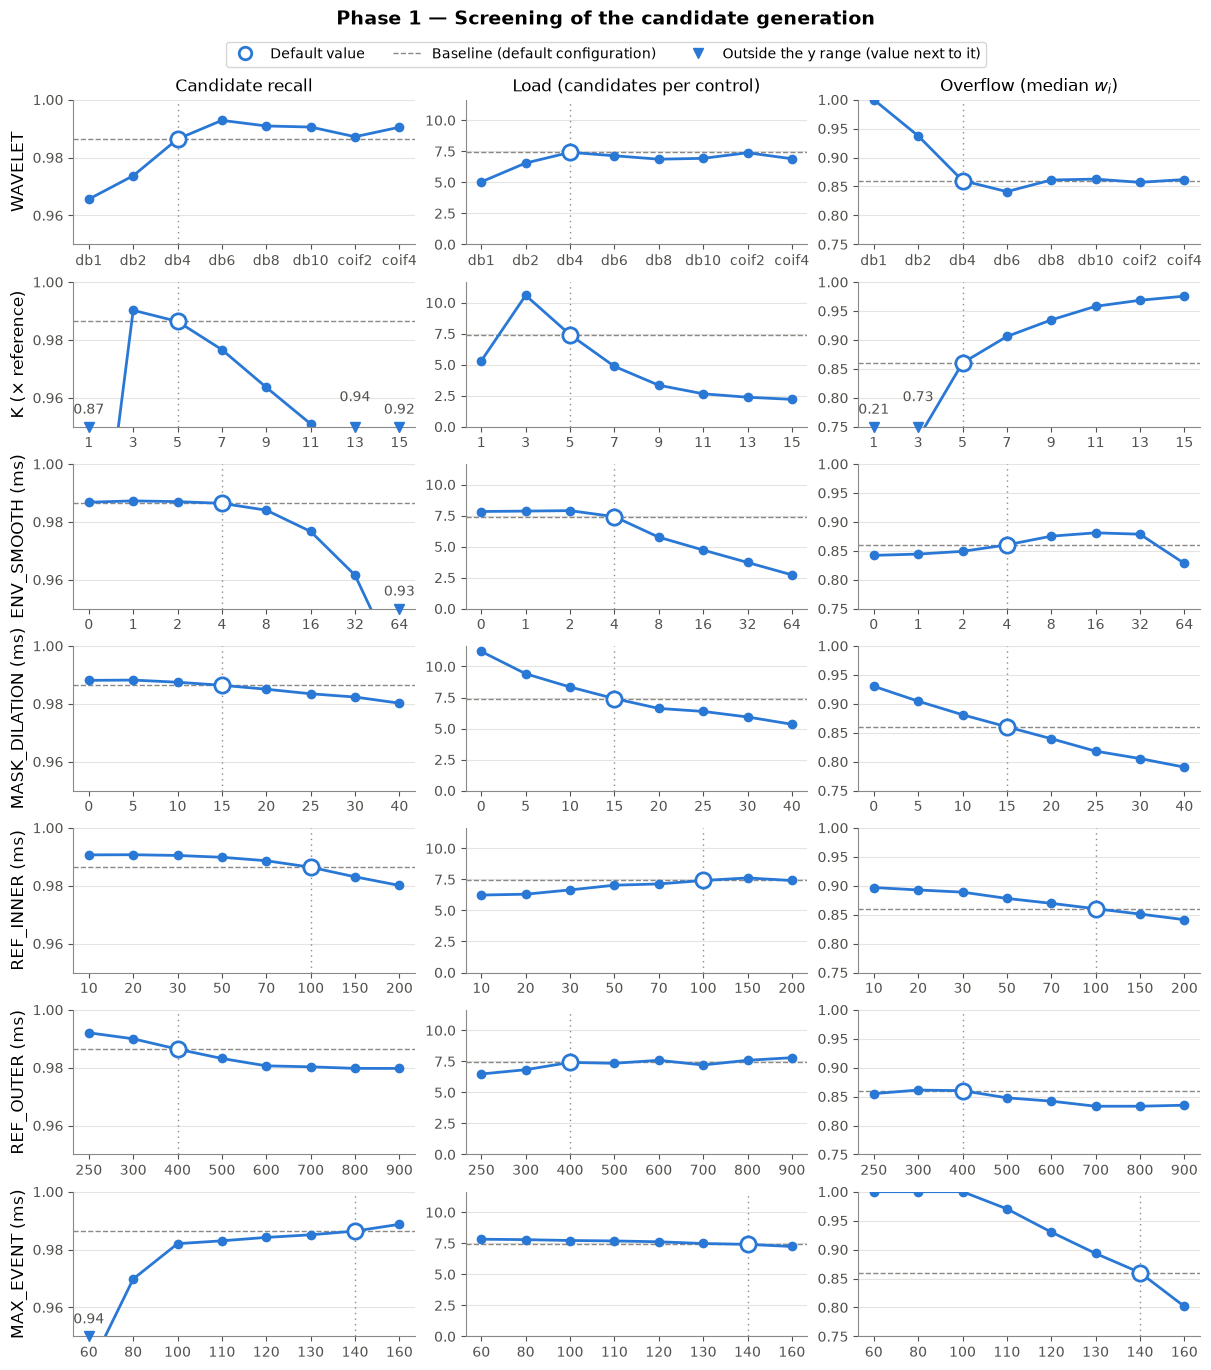

Range (max - min) of each metric:


,recall,load,w_med
WAVELET,0.0272,2.3793,0.1589
K,0.1207,8.3793,0.7688
ENV_SMOOTH,0.0582,5.1724,0.0529
MASK_DILATION,0.0080,5.8621,0.1397
REF_INNER,0.0106,1.3793,0.0556
REF_OUTER,0.0123,1.3103,0.0279
MAX_EVENT,0.0503,0.5862,0.1982


In [66]:
screening = load_screening()
print(f"Screened parameters: {', '.join(screening)}")

fig = plot_screening(screening)
plt.show()

print("Range (max - min) of each metric:")
screening_ranges(screening).style.format("{:.4f}")

In [70]:
def _screening_geometry(fig_w, fig_h, dpi, spec):
    """
    Geometry of the plot_screening figure as matplotlib computes it (layout="constrained"): builds the same figure
    WITHOUT data (titles, labels, limits, ticks, key and title) and returns the boxes (px from the top-left corner of
    the image cropped as bbox_inches="tight") of the axes, texts and key, and the y ticks of each column.
    spec: dict(rows=[dict(label, xticklabels, xlim)], cols=[dict(label, ylim)], handles=[Line2D], title)
    """
    rows, cols = spec["rows"], spec["cols"]
    fig = Figure(figsize=(fig_w, fig_h), dpi=dpi, layout="constrained")
    canvas = FigureCanvasAgg(fig)
    axs = fig.subplots(len(rows), len(cols), sharex="row", sharey="col", squeeze=False)

    for i, row in enumerate(rows):
        for j, col in enumerate(cols):
            ax = axs[i, j]
            if i == 0:
                ax.set_title(col["label"], fontsize=12)
            if j == 0:
                ax.set_ylabel(row["label"], fontsize=12)
                ax.set_xticks(range(len(row["xticklabels"])), row["xticklabels"])
                ax.set_xlim(*row["xlim"])
            if i == 0:
                ax.set_ylim(*col["ylim"])
            ax.spines[["top", "right"]].set_visible(False)

    fig.suptitle(spec["title"], fontsize=14, y=1.05, fontweight="bold")
    leg = fig.legend(handles=spec["handles"], loc="outside lower center", bbox_to_anchor=(0.5, 1), ncols=3,
                     fontsize=10)

    canvas.draw()
    r = canvas.get_renderer()
    tight = fig.get_tightbbox(r)
    pad = 0.1*dpi                                                                # pad_inches of bbox_inches="tight"
    x0, y_top = tight.x0*dpi - pad, tight.y1*dpi + pad

    def box(artist):
        bb = artist.get_window_extent(r)
        return dict(x0=bb.x0 - x0, x1=bb.x1 - x0, top=y_top - bb.y1, bottom=y_top - bb.y0)

    def yticks(ax):
        lo, hi = ax.get_ylim()
        eps = 1e-9*(hi - lo)
        return [(v, t.get_text()) for v, t in zip(ax.get_yticks(), ax.get_yticklabels()) if lo - eps <= v <= hi + eps]

    return dict(size=(int(tight.width*dpi + 2*pad), int(tight.height*dpi + 2*pad)), suptitle=box(fig._suptitle),
                legend=box(leg), legend_texts=[box(t) for t in leg.get_texts()],
                axes=[[box(ax) for ax in row] for row in axs], titles=[box(ax.title) for ax in axs[0]],
                ylabels=[box(ax.yaxis.label) for ax in axs[:, 0]], yticks=[yticks(ax) for ax in axs[0]])


def plot_screening(tables, metrics=SCREENING_METRICS, title="Phase 1 — Screening of the candidate generation",
                   width=None, dpi=100):
    """
    Interactive (plotly) version of plot_screening (matplotlib, cell above): same layout (layout="constrained", one
    row per parameter and one column per metric, the same y axis in each column), sizes, fonts, colors and positions.
    The figure is cropped as the inline backend does (bbox_inches="tight"), so its size matches the matplotlib image.
    - Ring and dotted vertical line: default value (remove_noise.py)
    - Dashed line: baseline (default configuration)
    - Triangle at the edge: value outside the y limits of the column (its value next to it)
    Interactivity: hover on every point with the value of the parameter and the three metrics; zoom in each panel (the
    x axis is common to the panels of a row and the y axis to the panels of a column, as sharex / sharey).
    The positions of the axes, texts and key are taken from the constrained layout of matplotlib applied to the same
    figure without data (_screening_geometry).
    Limits: the triangles and their values mark the initial limits (when zooming they stay at the same data value);
    the key is not clickable (it only explains the references); the plotly key symbols are not the matplotlib ones
    (at 5-35 px from the start of each item).

    Parameters
    ----------
    tables: dict
        {parameter: screening table} (load_screening)
    metrics: dict
        {metric (column of the tables): (label, y limits)}, one column of the figure each (see SCREENING_METRICS)
    title: str
        Title of the figure (above the key)
    width: int or None
        Width of the figure (px). Only the width of the axes changes (the fonts and the margins do not). None -> as
        matplotlib
    dpi: float
        px per inch (matplotlib inline: 100). Every size (fonts, lines, margins) scales with it

    Returns
    -------
    fig: go.Figure
        Interactive figure
    """
    params = list(tables)
    first = tables[params[0]]
    baseline = first.loc[first["default"]].iloc[0]  # Default configuration: the same row in every table
    n_cols = len(metrics)

    # y limits of each column: those of metrics, None -> as matplotlib autoscale (data of the column + 5 %)
    ylims = []
    for metric, (_, ylim) in metrics.items():
        auto = mpl_range(*[table[metric].to_numpy(float) for table in tables.values()], [baseline[metric]])
        lo, hi = ylim if ylim is not None else (None, None)
        ylims.append([auto[0] if lo is None else lo, auto[1] if hi is None else hi])

    # Key (matplotlib handles, for the geometry)
    handles = [
        Line2D([], [], ls="none", marker="o", ms=9, mfc="white", mec=SERIES_COLOR, mew=2, label="Default value"),
        Line2D([], [], color=REF_COLOR, lw=1, ls="--", label="Baseline (default configuration)"),
        Line2D([], [], ls="none", marker="v", ms=7, color=SERIES_COLOR, label="Outside the y range (value next to it)"),
    ]

    # --- Geometry (as matplotlib) ---
    PT = dpi/72                                                                    # px per point
    pt = lambda v: v*PT
    em = pt(10)                                                                    # font size of ticks and key (px)
    dash = lambda on, off: f"{pt(on):.1f}px,{pt(off):.1f}px"                       # dash pattern (pt, lw = 1)

    rows = [dict(label=param_title(param), xticklabels=[format_value(param, v) for v in tables[param]["value"]],
                 xlim=mpl_range(np.arange(len(tables[param])))) for param in params]
    spec = dict(rows=rows, cols=[dict(label=label, ylim=ylim) for (label, _), ylim in zip(metrics.values(), ylims)],
                handles=handles, title=title)

    fig_w, fig_h = 4*n_cols, 1.7*len(params) + 1
    geo = _screening_geometry(fig_w, fig_h, dpi, spec)
    for _ in range(6 if width else 0):                                             # requested width: only axes change
        if geo["size"][0] == width:
            break
        fig_w += (width - geo["size"][0])/dpi
        geo = _screening_geometry(fig_w, fig_h, dpi, spec)
    W, H = geo["size"]
    X = lambda v: v/W                                                              # px -> paper
    Y = lambda v: 1 - v/H

    def html(s):
        """matplotlib mathtext of a label ($w_i$) -> plotly HTML (<i>w</i><sub><i>i</i></sub>)"""
        return re.sub(r"\$([A-Za-z])_\{?([A-Za-z0-9]+)\}?\$", r"<i>\1</i><sub><i>\2</i></sub>", s)

    axis_style = dict(showline=True, linecolor=REF_COLOR, linewidth=pt(0.8), ticks="outside", ticklen=pt(3.5),
                      tickwidth=pt(0.8), tickcolor=TEXT_COLOR, tickfont=dict(size=em, color=TEXT_COLOR),
                      zeroline=False, automargin=False, layer="below traces")  # markers over the axes

    # y ticks of each column as matplotlib: its step from 0 and its decimals
    y_ticks = []
    for ticks in geo["yticks"]:
        values, labels = zip(*ticks)
        decimals = len(labels[0].split(".")[1]) if "." in labels[0] else 0
        y_ticks.append(dict(tickmode="linear", tick0=0, dtick=values[1] - values[0], tickformat=f".{decimals}f"))

    fig = go.Figure()
    layout, shapes, annotations = {}, [], []
    metric_names = [re.sub(r"\s*\(.*", "", html(label)) for label, _ in metrics.values()]   # for the hover

    for i, param in enumerate(params):
        table = tables[param]
        x = np.arange(len(table))
        is_default = table["default"].to_numpy(dtype=bool)

        # Hover: value of the parameter (default?) and the three metrics
        names = [format_value(param, v) + (" (default)" if d else "") for v, d in zip(table["value"], is_default)]
        custom = np.column_stack([names] + [table[metric].to_numpy(float) for metric in metrics]).astype(object)
        custom[:, 1:] = custom[:, 1:].astype(float)
        hover = (f"{html(param_title(param))} = %{{customdata[0]}}<br>"
                 + "<br>".join(f"{name}: %{{customdata[{m + 1}]:.4f}}" for m, name in enumerate(metric_names))
                 + "<extra></extra>")

        for j, metric in enumerate(metrics):
            k = i*n_cols + j + 1                                                   # axes number (row by row)
            a = "" if k == 1 else str(k)
            b = geo["axes"][i][j]
            x_row = "x" if i == 0 else f"x{i*n_cols + 1}"                          # sharex="row"
            y_col = "y" if j == 0 else f"y{j + 1}"                                 # sharey="col"
            layout[f"xaxis{a}"] = dict(domain=[X(b["x0"]), X(b["x1"])], anchor=f"y{a}", range=rows[i]["xlim"],
                                       tickmode="array", tickvals=x, ticktext=rows[i]["xticklabels"], showgrid=False,
                                       ticklabelstandoff=round(-2.2*PT), **({"matches": x_row} if j else {}),
                                       **axis_style)
            layout[f"yaxis{a}"] = dict(domain=[Y(b["bottom"]), Y(b["top"])], anchor=f"x{a}", range=ylims[j],
                                       showgrid=True, gridcolor=GRID_COLOR, gridwidth=pt(0.8), **y_ticks[j],
                                       **({"matches": y_col} if i else {}), **axis_style)
            axes = dict(xaxis=f"x{a}", yaxis=f"y{a}")
            y = table[metric].to_numpy(dtype=float)

            # References: baseline and default value (below the values)
            shapes.append(dict(type="line", xref=f"x{a} domain", yref=f"y{a}", x0=0, x1=1, y0=baseline[metric],
                               y1=baseline[metric], layer="below",
                               line=dict(color=REF_COLOR, width=pt(1), dash=dash(3.7, 1.6))))
            for x_default in x[is_default]:
                shapes.append(dict(type="line", xref=f"x{a}", yref=f"y{a} domain", x0=x_default, x1=x_default, y0=0,
                                   y1=1, layer="below", line=dict(color=REF_COLOR, width=pt(1), dash=dash(1, 3))))

            # Values (the default one with a ring)
            fig.add_trace(go.Scatter(x=x, y=y, mode="lines+markers", line=dict(color=SERIES_COLOR, width=pt(2)),
                                     marker=dict(size=pt(6), color=SERIES_COLOR,
                                                 line=dict(color=SERIES_COLOR, width=pt(1))),
                                     customdata=custom, hovertemplate=hover, showlegend=False, **axes))
            fig.add_trace(go.Scatter(x=x[is_default], y=y[is_default], mode="markers",
                                     marker=dict(size=pt(11), color="white", line=dict(color=SERIES_COLOR, width=pt(2))),
                                     customdata=custom[is_default], hovertemplate=hover, showlegend=False, **axes))

            # Values outside the y limits: triangle at the edge + value (at alternate heights, so that close values do
            # not overlap)
            lo, hi = ylims[j]
            outside = np.flatnonzero((y < lo) | (y > hi))
            below = y[outside] < lo
            fig.add_trace(go.Scatter(x=x[outside], y=np.where(below, lo, hi), mode="markers", cliponaxis=False,
                                     marker=dict(size=pt(8.5), color=SERIES_COLOR,
                                                 symbol=np.where(below, "triangle-down", "triangle-up"),
                                                 line=dict(color=SERIES_COLOR, width=pt(1))),
                                     customdata=custom[outside], hovertemplate=hover, showlegend=False, **axes))
            for n, (idx, is_below) in enumerate(zip(outside, below)):
                offset = pt(7 + 9*(n % 2))
                annotations.append(dict(text=f"{y[idx]:.2f}", x=x[idx], y=lo if is_below else hi, xref=f"x{a}",
                                        yref=f"y{a}", yshift=offset if is_below else -offset, showarrow=False,
                                        xanchor="center", yanchor="bottom" if is_below else "top", borderpad=0,
                                        font=dict(size=em, color=TEXT_COLOR)))

    # --- Key: one plotly legend per item, at the position of the matplotlib text (the text of a plotly item starts
    # 40 px to the right of the x of the legend), not clickable, and a frame with rounded corners ---
    items = [dict(mode="markers", marker=dict(size=pt(9), color="white", line=dict(color=SERIES_COLOR, width=pt(2)))),
             dict(mode="lines", line=dict(color=REF_COLOR, width=pt(1), dash=dash(3.7, 1.6))),
             dict(mode="markers", marker=dict(size=pt(8.5), color=SERIES_COLOR, symbol="triangle-down",
                                              line=dict(color=SERIES_COLOR, width=pt(1))))]
    legends = {}
    for n, (handle, item, t) in enumerate(zip(handles, items, geo["legend_texts"]), start=1):
        lid = "legend" if n == 1 else f"legend{n}"
        legends[lid] = dict(x=X(t["x0"] - 40), y=Y((t["top"] + t["bottom"])/2 - 0.1*em), xanchor="left",
                            yanchor="middle", orientation="h", bgcolor="rgba(0, 0, 0, 0)", borderwidth=0,
                            font=dict(size=em, color="black"), itemclick=False, itemdoubleclick=False, itemwidth=30)
        fig.add_trace(go.Scatter(x=[None], y=[None], name=handle.get_label(), legend=lid, hoverinfo="skip", **item))
    b = geo["legend"]
    shapes.append(dict(type="path", xref="paper", yref="paper", layer="above", fillcolor="rgba(255, 255, 255, 0.8)",
                       line=dict(color="#cccccc", width=pt(1)),
                       path=rounded_rect(X(b["x0"]), X(b["x1"]), Y(b["bottom"]), Y(b["top"]), 0.2*em, W, H)))

    # --- Title, metric of each column and parameter of each row ---
    def ann(s, b, size, rotate=False):
        """Text centered in the matplotlib box b (raised 0.1 em: Arial sits lower than DejaVu Sans)"""
        cx, cy = (b["x0"] + b["x1"])/2, (b["top"] + b["bottom"])/2
        if rotate:
            cx -= 0.1*pt(size)
        else:
            cy -= 0.1*pt(size)
        return dict(text=s, x=X(cx), y=Y(cy), xref="paper", yref="paper", xanchor="center", yanchor="middle",
                    showarrow=False, font=dict(size=pt(size), color="black"), textangle=-90 if rotate else 0)

    annotations.append(ann(f"<b>{title}</b>", geo["suptitle"], 14))
    annotations += [ann(html(label), box, 12) for (label, _), box in zip(metrics.values(), geo["titles"])]
    annotations += [ann(html(row["label"]), box, 12, rotate=True) for row, box in zip(rows, geo["ylabels"])]

    fig.update_layout(
        **layout, **legends, width=W, height=H, margin=dict(l=0, r=0, t=0, b=0, autoexpand=False),
        annotations=annotations, shapes=shapes, font=dict(family=FONT, size=em, color="black"),
        paper_bgcolor="white", plot_bgcolor="white", hovermode="closest", template="none"
    )
    return fig


fig = plot_screening(screening)
fig.show()

**Parameters of the search ([4.4](#4.4.-Search)):** every parameter changes the metrics, so none is fixed for that reason. `MAX_EVENT` is fixed for another one (see below).

| Parameter | Screened values | Search range | Scale | Effect in the screening |
|:----------|:----------------|:------------:|:-----:|:------------------------|
| `WAVELET`       | db1, db2, db4, db6, db8, db10, coif2, coif4 | {db6, db8, db10, db12, db16, db20, coif4, coif6, coif8, coif10, coif12, coif16} | Categorical | db8, db10 and coif4 improve db4 in the three metrics; db6 gives the highest recall, with a lower median $w_i$; db1 and db2 lose recall. Higher orders (db12 – db20) and the coif of the same orders (coif6 – coif16; coif20 does not exist) not screened |
| `K`             | 1 – 15             | [3, 11]       | Linear | Main trade-off: a lower `K` gives more recall, but more load and overflow; with `K` = 1 the candidates merge (recall and median $w_i$ fall) |
| `ENV_SMOOTH`    | 0 – 64 ms          | [2, 16] ms   | Log    | Below 4 ms, more load and overflow without recall; 8 ms lowers the load (−22 %) at a small recall cost; above 16 ms, the recall falls |
| `MASK_DILATION` | 0 – 40 ms          | [0, 30] ms   | Linear | Load vs overflow: less widening gives more load and less overflow; the recall barely changes |
| `REF_INNER`     | 10 – 200 ms        | [10, 70] ms  | Log    | Lower values improve the three metrics (default value: 100 ms); plateau below 20 ms |
| `REF_OUTER`     | 250 – 900 ms       | [100, 400] ms | Linear | Lower values improve the recall and the load; still improving at 250 ms (100 – 200 ms not screened) |

**Constraints:**

- `REF_INNER` < `REF_OUTER`.
- `REF_OUTER` − `REF_INNER` ≥ `MAX_EVENT` (140 ms): the reference is the median of two windows of `REF_OUTER` − `REF_INNER`, one at each side, so in an event longer than `REF_OUTER` the reference rises at the edges and only the center is detected (2·`REF_OUTER` − L for a flat event of length L < `REF_INNER` + `REF_OUTER`; longer events are not detected at all). With windows shorter than `MAX_EVENT`, that center can be shorter than `MAX_EVENT`: the event loses the protection of long events and becomes a short candidate.

**Fixed:** `MAX_EVENT` = 140 ms (screened: 60 – 160 ms). Higher values gain recall only with spans that overflow the artifact, and it is the limit of the protection of the adventitious sounds, which phase 1 does not measure. It is swept later with the Score.

### 4.4. Search

Two Bayesian optimizations, one after the other, both subject to `REF_INNER` < `REF_OUTER` and `REF_OUTER` − `REF_INNER` ≥ `MAX_EVENT` (see the parameters of the search in [4.3](#4.3.-Screening)):

- **(a) Maximum recall:** maximize the candidate recall (cost-weighted) → $\text{recall}_{\max}$ and its standard error $SE$ (bootstrap grouped by signal and by artifact).
- **(b) Minimum load:** minimize the load subject to recall ≥ $\text{recall}_{\max} - SE$ and median $w_i$ ≥ median $w_i$ of the baseline.
- **Safeguard:** if (b) finds no configuration that meets both constraints, $\text{recall}_{\max}$ and $SE$ are recomputed from the configurations of (a) with median $w_i$ ≥ median $w_i$ of the baseline, and (b) is run again.

The recall, load and overflow of every evaluated configuration (of both searches) are saved.

**Nested cross-validation** ([search_candidates.py](search_candidates.py), from the terminal): the tuning clean signals and artifacts are split into 5 folds (grouped and stratified as the tuning/test split); in fold *k*, the searches and the choice use the signals and artifacts of the other folds, and the C1 of the fold is evaluated (with the baseline) on those of fold *k* → 5 C1 (stability of the parameters) + 5 validation metrics (optimism). The final C1 comes from the same protocol on the whole tuning set.

**Results** ([search_candidates.py](search_candidates.py), in `results/optimization/candidates/search/`): only the finished runs (`<run>.json` and `<run>_trials.csv`) are loaded, so this section can be run while the other runs go on.

- **Table:** for each run, configurations evaluated in each search, configurations that meet the constraints of (b), safeguard, constraints of (b), and recall, load and median $w_i$ of the baseline and of C1 on the training mixtures of the run.
- **Figure (history):** one row per run; recall and load of each configuration in the order of evaluation. Color and marker: search; hollow: does not meet the constraints of (b). Line: best recall of (a) / minimum load of the configurations that meet the constraints so far (convergence of each search). Dotted line: recall constraint of (b); dashed line: baseline; star: C1.

In [ ]:
SEARCH_DIR = Path("results/optimization/candidates/search")  # Results of search_candidates.py
SEARCH_RUNS = [f"fold_{k}" for k in range(1, N_CV_FOLDS + 1)] + ["all"]
SEARCHED_PARAMS = [p for p in cs.SEARCH_PARAMS if p != "MAX_EVENT"]  # MAX_EVENT is fixed
SEARCH_RANGES = {"K": cs.K_RANGE, "ENV_SMOOTH": cs.ENV_SMOOTH_RANGE, "MASK_DILATION": cs.MASK_DILATION_RANGE,
                 "REF_INNER": cs.REF_INNER_RANGE, "REF_OUTER": cs.REF_OUTER_RANGE}
LOG_PARAMS = ["ENV_SMOOTH", "REF_INNER"]  # Searched in log scale

# Each search: color and marker (the identity is not carried by the color alone)
SEARCH_STYLE = {
    "a": dict(color="#2a78d6", marker="o", label="(a) Maximum recall"),
    "b": dict(color="#eb6834", marker="s", label="(b) Minimum load"),
    "b2": dict(color="#1baf7a", marker="^", label="(b2) Safeguard"),
}
BASELINE_STYLE = dict(color=REF_COLOR, lw=1, ls="--")                       # Baseline (as in the screening)
CONSTRAINT_STYLE = dict(color=TEXT_COLOR, lw=1.2, ls=(0, (1, 2)))           # Constraints of (b)
BASELINE_POINT = dict(ls="none", marker="D", ms=8, mfc="white", mec=REF_COLOR, mew=2)
C1_STYLE = dict(ls="none", marker="*", ms=17, color="black", mec="white", mew=1)


def run_title(run):
    """Name of a run in the figures and tables: fold_1 -> Fold 1, all -> All"""
    return "All" if run == "all" else run.replace("fold_", "Fold ")


def style_axes(ax):
    """Style of the axes of the figures of phase 1 (as plot_screening)"""
    ax.grid(axis="y", color=GRID_COLOR, lw=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(REF_COLOR)
    ax.tick_params(colors=TEXT_COLOR)


def search_handles(trials=None):
    """Key of the searches (only those present in trials, if given) and of the hollow markers"""
    searches = SEARCH_STYLE if trials is None else [s for s in SEARCH_STYLE if (trials["search"] == s).any()]
    handles = [Line2D([], [], ls="none", marker=SEARCH_STYLE[s]["marker"], ms=7, color=SEARCH_STYLE[s]["color"],
                      label=SEARCH_STYLE[s]["label"]) for s in searches]
    handles.append(Line2D([], [], ls="none", marker="o", ms=7, mfc="white", mec=REF_COLOR, mew=1.2,
                          label="Hollow: does not meet the constraints of (b)"))
    return handles


def plot_trials(ax, trials, x, y):
    """Configurations of trials at (x, y) (columns of trials): color and marker of their search, hollow if they do not
    meet the constraints of (b)"""
    for search, style in SEARCH_STYLE.items():
        for feasible in (False, True):
            d = trials[(trials["search"] == search) & (trials["feasible"] == feasible)]
            ax.plot(d[x], d[y], ls="none", marker=style["marker"], ms=6, color=style["color"],
                    mfc=style["color"] if feasible else "white", mew=1.2, zorder=3)


def load_search(path=SEARCH_DIR, runs=SEARCH_RUNS):
    """
    Results of search_candidates.py, only of the finished runs (<run>.json and <run>_trials.csv): {run: dict}
    - summary: dict, <run>.json (constraints of (b), safeguard, C1 and the metrics of C1 and of the baseline on the
      training mixtures and, in the folds, on the validation mixtures)
    - trials: pd.DataFrame, <run>_trials.csv (one row per evaluated configuration, in the order of evaluation: (a),
      (b), (b2)), with the column c1 (whether the configuration is C1)
    """
    results = {}
    for run in runs:
        json_path, csv_path = path / f"{run}.json", path / f"{run}_trials.csv"
        if not (json_path.exists() and csv_path.exists()):
            continue
        summary = json.loads(json_path.read_text(encoding="utf-8"))
        trials = pd.read_csv(csv_path, dtype={"search": str})
        trials["feasible"] = trials["feasible"].astype(bool)
        c1 = summary["c1"]
        trials["c1"] = False if c1 is None else (trials["search"] == c1["search"]) & (trials["trial"] == c1["trial"])
        results[run] = dict(summary=summary, trials=trials)
    if not results:
        raise FileNotFoundError(f"No finished run in {path} (run search_candidates.py)")
    return results


def search_overview(results):
    """
    One row per run: configurations evaluated in each search, configurations that meet the constraints of (b),
    safeguard, constraints of (b) (recall_min = recall_max - SE, w_min) and recall, load and median w_i of the
    baseline and of C1 on the training mixtures of the run
    """
    rows = {}
    for run, r in results.items():
        s, t = r["summary"], r["trials"]
        base, c1 = s["train"]["baseline"], s["train"].get("c1")
        row = {f"n_{search}": int((t["search"] == search).sum()) for search in SEARCH_STYLE}
        row.update(n_feasible=int(t["feasible"].sum()), safeguard=s["safeguard"], recall_max=s["recall_max"],
                   se=s["se"], recall_min=s["recall_min"], w_min=s["w_min"],
                   c1=f"{s['c1']['search']} #{s['c1']['trial']}" if s["c1"] else "—")
        for m in ("recall", "load", "w_med"):
            row[f"baseline_{m}"] = base[m]
            row[f"c1_{m}"] = c1[m] if c1 else np.nan
        rows[run_title(run)] = row
    return pd.DataFrame.from_dict(rows, orient="index")


def plot_search_history(results, title="Phase 1 — Bayesian search of the candidate generation"):
    """
    History of the searches of each run: one row per run and two columns, the candidate recall and the load of each
    evaluated configuration in the order of evaluation ((a), then (b) and (b2)).
    - Color and marker: search; hollow: does not meet the constraints of (b) (final ones of the run)
    - Recall: best recall of (a) so far (line) and recall constraint of (b) (recall_max - SE, dotted)
    - Load: minimum load so far of the configurations that meet the constraints of (b) (line)
    - Dashed line: baseline (training mixtures of the run); star: C1; dotted vertical lines: start of (b) and (b2)

    Parameters
    ----------
    results: dict
        Output of load_search
    title: str
        Title of the figure (above the key)

    Returns
    -------
    fig: matplotlib.figure.Figure
    """
    runs = list(results)
    fig, axs = plt.subplots(len(runs), 2, figsize=(12, 2.4*len(runs) + 1.2), squeeze=False, layout="constrained")
    columns = [("recall", "Candidate recall"), ("load", "Load (candidates per control)")]

    for i, run in enumerate(runs):
        s, t = results[run]["summary"], results[run]["trials"]
        base = s["train"]["baseline"]
        t = t.assign(n=np.arange(1, len(t) + 1))                                    # Order of evaluation

        # Best so far: recall of (a) and load of the configurations that meet the constraints of (b)
        is_a = t["search"] == "a"
        best_recall = np.maximum.accumulate(t["recall"].where(is_a, -np.inf).to_numpy()).astype(float)
        best_recall[~is_a.to_numpy()] = np.nan
        best_load = np.minimum.accumulate(t["load"].where(t["feasible"], np.inf).to_numpy()).astype(float)
        best_load[np.isinf(best_load)] = np.nan

        for j, (metric, label) in enumerate(columns):
            ax = axs[i, j]
            plot_trials(ax, t, "n", metric)
            ax.axhline(base[metric], **BASELINE_STYLE, zorder=1)
            for search in ("b", "b2"):                                              # Start of (b) and (b2)
                start = t.loc[t["search"] == search, "n"]
                if len(start):
                    ax.axvline(start.iloc[0] - 0.5, color=REF_COLOR, lw=1, ls=(0, (1, 3)), zorder=1)
            ax.plot(t.loc[t["c1"], "n"], t.loc[t["c1"], metric], **C1_STYLE, zorder=5)
            if i == 0:
                ax.set_title(label, fontsize=12)
            if i == len(runs) - 1:
                ax.set_xlabel("Evaluated configuration (order of evaluation)")
            style_axes(ax)

        axs[i, 0].plot(t["n"], best_recall, color=TEXT_COLOR, lw=1.5, drawstyle="steps-post", zorder=2)
        axs[i, 0].axhline(s["recall_min"], **CONSTRAINT_STYLE, zorder=1)
        axs[i, 1].plot(t["n"], best_load, color=TEXT_COLOR, lw=1.5, drawstyle="steps-post", zorder=2)
        axs[i, 0].set_ylabel(run_title(run) + (" (safeguard)" if s["safeguard"] else ""), fontsize=12)

    handles = search_handles() + [
        Line2D([], [], color=TEXT_COLOR, lw=1.5, label="Best so far (recall of (a) / feasible load)"),
        Line2D([], [], **CONSTRAINT_STYLE, label="Recall constraint of (b)"),
        Line2D([], [], **BASELINE_STYLE, label="Baseline"),
        Line2D([], [], **C1_STYLE, label="C1"),
    ]
    fig.suptitle(title, fontsize=14, fontweight="bold")
    fig.legend(handles=handles, loc="outside upper center", ncols=4, fontsize=10)
    return fig


search = load_search()
print(f"Finished runs: {', '.join(run_title(run) for run in search)}")
display(search_overview(search).style.format(precision=4))

fig = plot_search_history(search)
plt.show()

### 4.5. Choice

Among all the evaluated configurations (a and b) that meet the constraints of (b), the one with the minimum load → **C1**.

- **Check:** load–overflow Pareto front of those configurations (e.g. whether a little more load would give much less overflow).

**Figures and tables:**

- **Choice** (whole tuning set; the last finished fold until then): recall–load of every configuration, with the recall constraint, and load–overflow of the configurations that meet it, with its Pareto front and the overflow constraint. Diamond: baseline; star: C1.
- **Pareto front:** configurations of the front, with their parameters and metrics.
- **Parameters of C1:** baseline, C1 of each run and search range.
- **Nested cross-validation:** for each fold, C1 − baseline on the training mixtures (where C1 was chosen) and on the validation mixtures (new signals and artifacts); the distance between both is the optimism (improvement on training − improvement on validation).
- **Stability of C1:** value of each parameter in the C1 of each fold and of the whole tuning set, with the search range and the baseline.

In [ ]:
def pareto_front(trials, recall_min):
    """
    Load–overflow Pareto front of the configurations with recall >= recall_min: those that no other one improves at
    once in load (lower) and median w_i (higher), sorted by load
    """
    ok = trials[trials["recall"] >= recall_min].sort_values(["load", "w_med"], ascending=[True, False])
    return ok[ok["w_med"] > ok["w_med"].cummax().shift(fill_value=-np.inf)]


def plot_choice(results, run="all", title="Phase 1 — Choice of C1"):
    """
    Choice of C1 of a run, in two panels:
    - Recall–load: every evaluated configuration, with the recall constraint of (b) (recall_max - SE, dotted)
    - Load–overflow: the configurations that meet the recall constraint, their Pareto front (line), and the overflow
      constraint of (b) (median w_i of the baseline, dotted)
    Color and marker: search; hollow: does not meet the constraints of (b); diamond: baseline (training mixtures of the
    run); star: C1 (minimum load among the configurations that meet both constraints)

    Parameters
    ----------
    results: dict
        Output of load_search
    run: str
        Run (fold_1 ... fold_5, all)
    title: str
        Title of the figure (the run is added)

    Returns
    -------
    fig: matplotlib.figure.Figure
    """
    s, t = results[run]["summary"], results[run]["trials"]
    base = s["train"]["baseline"]
    c1 = t[t["c1"]]
    fig, (ax_r, ax_w) = plt.subplots(1, 2, figsize=(12, 5.5), layout="constrained")

    # Recall–load: every configuration
    plot_trials(ax_r, t, "load", "recall")
    ax_r.axhline(s["recall_min"], **CONSTRAINT_STYLE, zorder=1)
    ax_r.plot(base["load"], base["recall"], **BASELINE_POINT, zorder=4)
    ax_r.plot(c1["load"], c1["recall"], **C1_STYLE, zorder=5)
    ax_r.set(xlabel="Load (candidates per control)", ylabel="Candidate recall")
    ax_r.set_title("Recall–load (every configuration)", fontsize=12)

    # Load–overflow: configurations that meet the recall constraint, and their Pareto front
    ok = t[t["recall"] >= s["recall_min"]]
    front = pareto_front(t, s["recall_min"])
    plot_trials(ax_w, ok, "load", "w_med")
    ax_w.plot(front["load"], front["w_med"], color=TEXT_COLOR, lw=1.5, drawstyle="steps-post", zorder=2)
    ax_w.axhline(s["w_min"], **CONSTRAINT_STYLE, zorder=1)
    ax_w.plot(base["load"], base["w_med"], **BASELINE_POINT, zorder=4)
    ax_w.plot(c1["load"], c1["w_med"], **C1_STYLE, zorder=5)
    ax_w.set(xlabel="Load (candidates per control)", ylabel="Overflow (median $w_i$)")
    ax_w.set_title(f"Load–overflow (recall ≥ {s['recall_min']:.4f})", fontsize=12)

    for ax in (ax_r, ax_w):
        style_axes(ax)

    handles = search_handles(t) + [
        Line2D([], [], **CONSTRAINT_STYLE, label="Constraint of (b)"),
        Line2D([], [], color=TEXT_COLOR, lw=1.5, label="Pareto front"),
        Line2D([], [], **BASELINE_POINT, label="Baseline"),
        Line2D([], [], **C1_STYLE, label="C1"),
    ]
    fig.suptitle(f"{title} ({run_title(run)})", fontsize=14, fontweight="bold")
    fig.legend(handles=handles, loc="outside upper center", ncols=4, fontsize=10)
    return fig


def format_param(param, value):
    """Value of a parameter in the tables (times in ms)"""
    if isinstance(value, str):
        return value
    return f"{1000*value:.1f}" if param in TIME_PARAMS else f"{value:.2f}"


def c1_params_table(results):
    """Parameters of the baseline (remove_noise.py), of the C1 of each run and search range (times in ms)"""
    def search_range(param):
        if param == "WAVELET":
            return ", ".join(cs.WAVELETS)
        if param == "MAX_EVENT":
            return "Fixed"
        lo, hi = SEARCH_RANGES[param]
        scale = 1000 if param in TIME_PARAMS else 1
        lo_text = f"max({scale*lo:g}, REF_INNER + MAX_EVENT)" if param == "REF_OUTER" else f"{scale*lo:g}"
        return f"{lo_text} – {scale*hi:g}" + (" (log)" if param in LOG_PARAMS else "")

    table = {"Baseline": {p: format_param(p, getattr(rn, p)) for p in cs.SEARCH_PARAMS}}
    for run, r in results.items():
        c1 = r["summary"]["c1"]
        table[run_title(run)] = {p: format_param(p, c1["params"][p]) if c1 else "—" for p in cs.SEARCH_PARAMS}
    table["Search range"] = {p: search_range(p) for p in cs.SEARCH_PARAMS}
    table = pd.DataFrame(table)
    table.index = [param_title(p) for p in table.index]
    return table


choice_run = "all" if "all" in search else list(search)[-1]  # Final C1 (whole tuning set), if already finished
fig = plot_choice(search, choice_run)
plt.show()

s = search[choice_run]["summary"]
print(f"Load–overflow Pareto front ({run_title(choice_run)}) of the configurations with recall >= "
      f"{s['recall_min']:.4f} (feasible: also median w_i >= {s['w_min']:.4f}; times in ms)")
front = pareto_front(search[choice_run]["trials"], s["recall_min"])
display(front[["search", "trial", *cs.SEARCH_PARAMS, "recall", "load", "w_med", "overflow_ms_med", "feasible", "c1"]]
        .style.format(precision=4)
        .format({p: lambda v, p=p: format_param(p, v) for p in cs.SEARCH_PARAMS}))

print("Parameters of the baseline and of C1 (times in ms)")
display(c1_params_table(search))

In [ ]:
CV_METRICS = {metric: label for metric, (label, _) in SCREENING_METRICS.items()}  # recall, load, w_med
BETTER = {"recall": 1, "load": -1, "w_med": 1}  # Sign of an improvement (the load is minimized)
CV_STYLE = {
    "train": dict(color="#2a78d6", marker="o", mfc="white", label="Training"),
    "val": dict(color="#eb6834", marker="s", label="Validation"),
}


def cv_table(results, metrics=CV_METRICS):
    """
    Nested cross-validation: for each finished fold, the metrics of the baseline and of C1 on the training and on the
    validation mixtures of the fold, the difference C1 - baseline on each (d_train, d_val) and the optimism
    (improvement on training - improvement on validation; > 0: C1 improves less on new signals and artifacts), with
    the mean and the SD over the folds.

    Returns
    -------
    table: pd.DataFrame
        One row per fold (+ Mean, SD); columns (metric, quantity)
    """
    rows = {}
    for run, r in results.items():
        s = r["summary"]
        if run == "all" or s["c1"] is None or not s.get("validation"):
            continue
        row = {}
        for m in metrics:
            tb, tc = s["train"]["baseline"][m], s["train"]["c1"][m]
            vb, vc = s["validation"]["baseline"][m], s["validation"]["c1"][m]
            row.update({(m, "train_baseline"): tb, (m, "train_c1"): tc, (m, "val_baseline"): vb, (m, "val_c1"): vc,
                        (m, "d_train"): tc - tb, (m, "d_val"): vc - vb,
                        (m, "optimism"): BETTER[m]*((tc - tb) - (vc - vb))})
        rows[run_title(run)] = row
    if not rows:
        raise ValueError("No fold finished (with C1 and its validation) yet")
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.columns = pd.MultiIndex.from_tuples(table.columns)
    return pd.concat([table, table.mean().to_frame("Mean").T, table.std().to_frame("SD").T])


def plot_cv(results, metrics=CV_METRICS, title="Phase 1 — Nested cross-validation: C1 vs baseline"):
    """
    Difference C1 - baseline of each metric in each fold, on the training mixtures of the fold (where C1 was chosen)
    and on its validation mixtures (new signals and artifacts), and mean ± SD over the folds. The distance between
    both is the optimism. Dashed line: baseline (difference 0).

    Parameters
    ----------
    results: dict
        Output of load_search
    metrics: dict
        {metric: label}, one panel each

    Returns
    -------
    fig: matplotlib.figure.Figure
    """
    table = cv_table(results, metrics)
    folds = table.index[:-2]
    x = np.arange(len(folds))
    x_mean = len(folds) + 0.5
    fig, axs = plt.subplots(1, len(metrics), figsize=(4*len(metrics), 4.2), squeeze=False, layout="constrained")

    for ax, (m, label) in zip(axs[0], metrics.items()):
        d = {part: table.loc[folds, (m, f"d_{part}")].to_numpy(float) for part in CV_STYLE}
        ax.axhline(0, **BASELINE_STYLE, zorder=1)
        ax.plot(np.vstack([x - 0.12, x + 0.12]), np.vstack([d["train"], d["val"]]), color=REF_COLOR, lw=1, zorder=2)
        for offset, (part, style) in zip((-0.12, 0.12), CV_STYLE.items()):
            style = {k: v for k, v in style.items() if k != "label"}
            ax.plot(x + offset, d[part], ls="none", ms=8, mew=1.5, zorder=3, **style)
            ax.errorbar(x_mean + offset, table.loc["Mean", (m, f"d_{part}")], yerr=table.loc["SD", (m, f"d_{part}")],
                        ls="none", ms=8, mew=1.5, capsize=4, elinewidth=1.5, zorder=3, **style)
        ax.axvline(len(folds) - 0.25, color=REF_COLOR, lw=1, ls=(0, (1, 3)), zorder=1)
        ax.set_xticks([*x, x_mean], [f.replace("Fold ", "") for f in folds] + ["Mean ± SD"])
        ax.set_xlabel("Fold")
        ax.set_title(label + (" ↓" if BETTER[m] < 0 else " ↑"), fontsize=12)
        style_axes(ax)
    axs[0, 0].set_ylabel("C1 − baseline")

    handles = [Line2D([], [], ls="none", ms=8, mew=1.5, **style) for style in CV_STYLE.values()]
    handles.append(Line2D([], [], **BASELINE_STYLE, label="Baseline"))
    fig.suptitle(title, fontsize=14, fontweight="bold")
    fig.legend(handles=handles, loc="outside upper center", ncols=3, fontsize=10)
    return fig


def plot_c1_stability(results, params=SEARCHED_PARAMS, title="Phase 1 — Stability of C1"):
    """
    Value of each searched parameter in the C1 of each fold and of the whole tuning set (All).
    - Shaded band: search range (REF_OUTER: from 150 ms; its real lower limit is max(150, REF_INNER + MAX_EVENT))
    - Dashed line: baseline (remove_noise.py); star: C1 of the whole tuning set (final C1)
    - Time parameters in ms; ENV_SMOOTH and REF_INNER in log scale (as in the search)

    Parameters
    ----------
    results: dict
        Output of load_search
    params: list
        Parameters, one panel each (3 per row)

    Returns
    -------
    fig: matplotlib.figure.Figure
    """
    runs = [run for run in results if results[run]["summary"]["c1"] is not None]
    if not runs:
        raise ValueError("No run with C1 yet")
    x = np.arange(len(runs))
    is_all = np.array([run == "all" for run in runs])
    n_cols = 3
    n_rows = -(-len(params) // n_cols)
    fig, axs = plt.subplots(n_rows, n_cols, figsize=(4*n_cols, 3.2*n_rows + 1), squeeze=False, layout="constrained")

    for ax, p in zip(axs.flat, params):
        values = [results[run]["summary"]["c1"]["params"][p] for run in runs]
        base = getattr(rn, p)
        if p == "WAVELET":                                       # Categorical: one row per wavelet
            categories = list(dict.fromkeys([base] + cs.WAVELETS))
            y = np.array([categories.index(v) for v in values], dtype=float)
            y_base = categories.index(base)
            searched = [categories.index(w) for w in cs.WAVELETS]
            band = (min(searched) - 0.5, max(searched) + 0.5)
            ax.set_yticks(range(len(categories)), categories)
            ax.set_ylim(-0.5, len(categories) - 0.5)
        else:
            scale = 1000 if p in TIME_PARAMS else 1
            y, y_base = scale*np.array(values, dtype=float), scale*base
            band = tuple(scale*v for v in SEARCH_RANGES[p])
            if p in LOG_PARAMS:
                ax.set_yscale("log")
        ax.axhspan(*band, color=GRID_COLOR, alpha=0.6, lw=0, zorder=0)
        ax.axhline(y_base, **BASELINE_STYLE, zorder=1)
        ax.plot(x[~is_all], y[~is_all], ls="none", marker="o", ms=8, color=SERIES_COLOR, zorder=3)
        ax.plot(x[is_all], y[is_all], **C1_STYLE, zorder=5)
        ax.set_xticks(x, ["All" if run == "all" else run.removeprefix("fold_") for run in runs])
        ax.set_xlim(-0.5, len(runs) - 0.5)
        ax.set_xlabel("Fold")
        ax.set_title(param_title(p), fontsize=12)
        style_axes(ax)
    for ax in axs.flat[len(params):]:
        ax.set_visible(False)

    handles = [
        Line2D([], [], ls="none", marker="o", ms=8, color=SERIES_COLOR, label="C1 of each fold"),
        Line2D([], [], **C1_STYLE, label="C1 of the whole tuning set"),
        Line2D([], [], **BASELINE_STYLE, label="Baseline"),
        Patch(color=GRID_COLOR, alpha=0.6, lw=0, label="Search range"),
    ]
    fig.suptitle(title, fontsize=14, fontweight="bold")
    fig.legend(handles=handles, loc="outside upper center", ncols=4, fontsize=10)
    return fig


print("Nested cross-validation: metrics of the baseline and of C1 on the training and validation mixtures of each "
      "fold, difference C1 - baseline (d) and optimism (improvement on training - improvement on validation)")
display(cv_table(search).style.format(precision=4))

fig = plot_cv(search)
plt.show()

fig = plot_c1_stability(search)
plt.show()

### 4.6. Full run

Computation of the estimates needed for the Score in [Phase 3](#6.-Phase-3:-Rule-selection).

## 5. Phase 2: Feature definition

- **Goal:** measure each feature so that it separates the artifacts from the rest as well as possible. The candidates are those of C1 and do not change.
- **Metric:** standardized partial ROC-AUC with a false positive rate ≤ 0.1, within the cases where each feature is used.
- **Output:** candidate table.

### 5.1. Width

- **Features:** `width_med`, `width_max`.
- **Parameters:** `BG_FACTOR`, `WIDTH_FLOOR_DB`, `EXTEND`.

### 5.2. Isolation

- **Feature:** `isolation`.
- **Parameter:** `ISO_WIN`.

### 5.3. Impulsiveness

- **Feature:** `z_max`.
- **Parameters:** `Z_WIN`, `AR_ORDER`.

### 5.4. Choice

Combination with the best mean partial AUC of each group (AUC vs value of each parameter).

### 5.5. Candidate table

Features of every candidate with the chosen parameters.

## 6. Phase 3: Rule selection

- **Goal:** define the rule matrix: 4 cases × 8 features (see [6️⃣ Click rules](README.md#6️⃣-click-rules)).
- **Metric:** $\hat{S}$ (estimated score).
- **Output:** final rule structure and thresholds.

### 6.1. Descriptive analysis

- Distributions of the features per class.
- Pairwise scatter plots per class.
- Correlation matrix.

### 6.2. Univariate analysis

For each case:

1. **Filter** with the main condition of the case.
2. **Minimum condition:** $SE \leq 0.03$ (bootstrap grouped by signal and by artifact); otherwise, relax the filter one percentile and repeat (adaptive margin at the relaxation limit: $|AUC - 0.5| \geq \max(0.1,\ 3 \cdot SE)$).
3. **Prefilter:** AUC of each of the other 7 features → condition ≥ / ≤ / not added ($|AUC - 0.5| \leq 0.1$).

**Output:** AUC matrix (case × feature).

### 6.3. Provisional optimization

- **Goal:** estimate the Score of a rule set from its detections on the candidate table, without running the filter. Same mean as $Q$ ([2.2](#2.2.-Global-quality)), with the quality of each cell $k = (s, a, c)$ split into its detected and undetected parts:

$$
\hat{S} = \frac{1}{|\mathcal{S}| |\mathcal{A}| |\mathcal{C}|}\sum_{s\in\mathcal{S}}\sum_{a\in\mathcal{A}}\sum_{c\in\mathcal{C}}\left[\widehat{\text{Det}}_{s,a,c}\cdot \hat{q}^{\text{det}}_{s,a,c} + \left(1-\widehat{\text{Det}}_{s,a,c}\right)\cdot \hat{q}^{\text{undet}}_{s,a,c}\right] - \lambda \cdot \widehat{FP}
$$

- $\widehat{\text{Det}}_{s,a,c}$: fraction of the $N_{a,c}$ positions of the cell detected by the rules.
- $\hat{q}^{\text{det}}_{s,a,c}$ / $\hat{q}^{\text{undet}}_{s,a,c}$: quality of the detected / undetected positions of the cell used by $\hat{S}$: the values $\bar{q}_k^{\text{det}}$ / $\bar{q}_k^{\text{undet}}$ measured in the full run ([4.6](#4.6.-Full-run)), or imputed when missing ([Imputation](#Imputation)). They do not depend on the rules: only $\widehat{\text{Det}}_{s,a,c}$ and $\widehat{FP}$ change.
- $\widehat{FP}$: number of false positives with the rules, averaged as $FP$.

#### Decomposition of the quality

$\hat{S}$ only uses the cell level; the aggregated means are used for $\lambda$ ([3.2](#3.2.-Penalty-λ)) and the [imputation](#Imputation).

**Cell:** if $p_k$ is the fraction of the positions of cell $k$ detected in the full run, and $\bar{q}_k^{\text{det}}$ and $\bar{q}_k^{\text{undet}}$ are the mean $q$ of its detected and undetected positions:

$$
\bar{q}_k = p_k\cdot \bar{q}_k^{\text{det}} + (1-p_k)\cdot \bar{q}_k^{\text{undet}}
$$

The term in brackets of $\hat{S}$ is this decomposition with $p_k$ replaced by $\widehat{\text{Det}}_{s,a,c}$, keeping $\bar{q}_k^{\text{det}}$ and $\bar{q}_k^{\text{undet}}$ from the full run. With the detections of the full run, $\hat{S} = S$ exactly. With other rules, $\hat{S}$ is an approximation: it assumes that only the fraction of detected positions changes, but the real $q$ of the cell can also change (e.g. the positions that become detected may be harder to attenuate than those already detected). The real $S$ is computed in [Phase 4](#7.-Phase-4:-Attenuation).

**Aggregated means** (per artifact $\bar{q}_{s,a}$, per SNR $\bar{q}_s$): weighted mean of the detected ($\mathcal{D}$) or undetected ($\mathcal{U}$) mixtures, each one with its weight in $Q$:

$$
w_i = \frac{1}{N_{a,c}}, \qquad
\bar{q}^{\text{det}} = \frac{\sum\limits_{i\in\mathcal{D}} w_i\, q_i}{\sum\limits_{i\in\mathcal{D}} w_i}, \qquad
\bar{q}^{\text{undet}} = \frac{\sum\limits_{i\in\mathcal{U}} w_i\, q_i}{\sum\limits_{i\in\mathcal{U}} w_i}
$$

With these weights, the decomposition also holds per SNR, with $\text{Det}_s$ the mean over $a, c$ of $p_k$:

$$
Q_s = \text{Det}_s\cdot \bar{q}^{\text{det}}_s + \left(1-\text{Det}_s\right)\cdot \bar{q}^{\text{undet}}_s
$$

#### Imputation

A value is missing when an artifact is never detected (or never missed) in a cell in the full run, but the new rules do detect (or miss) it. Each value used by $\hat{S}$ is taken from the closest level with data:

- **$\hat{q}^{\text{undet}}_{s,a,c}$:** $\bar{q}_k^{\text{undet}}$; if missing, the filter does not touch the zone of the artifact, so $\text{SNR}^{\text{out}} \approx s$ and $\hat{q}^{\text{undet}}_{s,a,c} \approx q(s)$ (to be checked with the measured values).
- **$\hat{q}^{\text{det}}_{s,a,c}$:** $\bar{q}_k^{\text{det}}$; if missing, $\bar{q}^{\text{det}}_{s,a}$ (same artifact in the other clean signals); if the artifact is not detected in any clean signal at that SNR, $\bar{q}^{\text{det}}_s$.

> If the full run gives $q^{\text{det}}$ of every mixture (forcing the attenuation of its candidate), no imputation is needed.

#### Procedure

1. **Search:** Bayesian optimization over the conditions that passed the prefilter, maximizing $\hat{S}$.
2. **Cross-validation:** 5 folds → 5 sets of thresholds + 5 values of $\hat{S}$.

### 6.4. Importance of each condition

| Measure | Definition |
|:--------|:-----------|
| **Unique rejections** | Number of candidates that meet every condition except this one and that this condition rejects |
| **Ablation** | $\Delta\hat{S}$ when it is disabled |
| **Stability** | Variability of the threshold across folds |
| **Unique detections per case** | Number of artifacts detected by that case and by no other |

**Output:** importance table (initial).

### 6.5. Backward pruning

1. **Pruning:** remove the condition with the highest $\Delta\hat{S}$.
2. **Optimization:** re-optimize the remaining thresholds.
3. **Repeat** until reaching a rule with a single condition.
4. **1-SE rule:** choose the simplest rule set whose $\hat{S}$ is within 1 SE of the best.
5. **Final thresholds:** optimize the thresholds of the remaining conditions on the whole tuning table.

**Outputs:** pruning curve, importance table (final), final rule structure and thresholds.

## 7. Phase 4: Attenuation

- **Optimization of:** `G_FAC`, `GAIN_SMOOTH`, `LOCAL_BG`.
- **Metric:** Score.
- **Output:** the optimized version.

## 8. Phase 5: Validation

- **Metrics:** S, Q, FP.
- **Output:** comparison and generalization.

### 8.1. Sensitivity to λ

Rule selection as a function of the value of $\lambda$.

### 8.2. Comparison

- S (Q, FP) for different values of $\lambda$.
- Wilcoxon signed-rank test, 95 % bootstrap CI of ΔS and number of signals that improve.

### 8.3. Generalization

Optimism = ΔS of the tuning set − ΔS of the test sets (test, new signals and new artifacts).